## 11. Hypothesis and exploratory analysis

## hypothesis

In [298]:
from pathlib import Path
import os
import warnings

import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import scipy.stats as stats
from sklearn.metrics import roc_auc_score
import matplotlib.ticker as mticker
from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency
from lifelines.statistics import multivariate_logrank_test
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

import matplotlib.ticker as mtick

from eda.clinical_definitions import (
    ICD9_INFO,
    SUBGROUP_LABELS,
    classify_system,
    classify_subgroup,
    classify_acute_chronic,
)

In [299]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

In [300]:
ROOT = Path(
    os.environ.get(
        "BIOSTAT_ROOT",
        "/Users/xinyichen/Desktop/BiostatisticsPracticum_Depression",
    )
)

OUTDIR = ROOT / "final_cohort" / "results" / "tables"
OUTDIR.mkdir(parents=True, exist_ok=True)

DF_CSV = OUTDIR / "final_analysis_long.csv"

print(DF_CSV)
df = pd.read_csv(DF_CSV, dtype=str)
print(df.shape)

/Users/xinyichen/Desktop/BiostatisticsPracticum_Depression/final_cohort/results/tables/final_analysis_long.csv
(238279, 52)


In [301]:
print(df.columns.tolist())
print(df.head())

['Patient_ID', 'window', 'window_days', 'Sex', 'Age', 'Any_Pre_existing_condition', 'Pre_existing_condition_count', 'first_mental_date', 'first_msk_date', 'Mental_Diagnosis_count', 'Mental_Diagnosis_list', 'Mental_Diagnosis_ICD9_list', 'Mental_Group_acute', 'Mental_Group_chronic', 'Mental_Group_symptom', 'Overall_Mental_group', 'Multimorbidity_count', 'Any_Mental_related_medication', 'Mental_related_medication_class_count', 'Mental_related_medication_drug_count', 'Any_Pain_related_medication', 'Pain_related_medication_class_count', 'Pain_related_medication_drug_count', 'Mental_related_medication_class_list', 'Mental_related_medication_drug_list', 'Pain_related_medication_class_list', 'Pain_related_medication_drug_list', 'MSK_Diagnosis', 'MSK_subgroup', 'MSK_subgroup_ICD9', 'time_to_msk_days', 'mental_anti_anxiety', 'mental_antidepressant', 'mental_antipsychotic', 'mental_hypnotic', 'pain_acetaminophen', 'pain_muscle_relaxant', 'pain_nsaid', 'pain_opioid', 'msk_3m', 'msk_6m', 'msk_9m', 

In [302]:
df.groupby("Patient_ID").size().describe()

count    38431.000000
mean         6.200177
std          2.829361
min          1.000000
25%          4.000000
50%          6.000000
75%          8.000000
max         14.000000
dtype: float64

In [303]:
sex_colors = {
    "F": "#4C78A8",
    "M": "#9ECAE9"
}

mental_colors = {
    "chronic": "#4C78A8",
    "acute": "#72B7B2",
    "both": "#9ECAE9",
    "symptom": "#BFD7EA"
}

## 1 Year df

In [304]:
df = df.copy()

if "window_days" in df.columns:
    df["window_days"] = pd.to_numeric(df["window_days"], errors="coerce")

if "MSK_Diagnosis" in df.columns:
    df["MSK_Diagnosis"] = pd.to_numeric(df["MSK_Diagnosis"], errors="coerce").fillna(0).astype(int)

if "time_to_msk_days" in df.columns:
    df["time_to_msk_days"] = pd.to_numeric(df["time_to_msk_days"], errors="coerce")

# sort so tail(1) 
df = df.sort_values(["Patient_ID", "window_days"]).reset_index(drop=True)


df_within_1yr = df[df["window_days"] <= 365].copy()

print("Within 1yr shape:", df_within_1yr.shape)
print("Unique patients within 1yr:", df_within_1yr["Patient_ID"].nunique())


df_1yr = (
    df_within_1yr
    .groupby("Patient_ID", as_index=False)
    .tail(1)
    .copy()
)

# outcome for 1 year
df_1yr["MSK_Diagnosis_1yr"] = (
    df_1yr["time_to_msk_days"].notna() &
    (df_1yr["time_to_msk_days"] <= 365)
).astype(int)

# final sort
df_1yr = df_1yr.sort_values("Patient_ID").reset_index(drop=True)


print("\nFinal df_1yr shape:", df_1yr.shape)
print("Unique patients:", df_1yr["Patient_ID"].nunique())
print("Duplicated Patient_ID:", df_1yr["Patient_ID"].duplicated().sum())
print("\nMSK_Diagnosis_1yr counts:")
print(df_1yr["MSK_Diagnosis_1yr"].value_counts(dropna=False).sort_index())

print("\nSelected window distribution:")
print(df_1yr["window"].value_counts(dropna=False).sort_index())

save_path = OUTDIR / "df_1yr_from_long.csv"
df_1yr.to_csv(save_path, index=False)

print("\nSaved to:", save_path)

Within 1yr shape: (168412, 52)
Unique patients within 1yr: 38431

Final df_1yr shape: (38431, 53)
Unique patients: 38431
Duplicated Patient_ID: 0

MSK_Diagnosis_1yr counts:
MSK_Diagnosis_1yr
0    24712
1    13719
Name: count, dtype: int64

Selected window distribution:
window
1m      1259
1yr    27634
3m      2751
6m      3667
9m      3120
Name: count, dtype: int64

Saved to: /Users/xinyichen/Desktop/BiostatisticsPracticum_Depression/final_cohort/results/tables/df_1yr_from_long.csv


## Demographic(Age,sex,mental, condition)

/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/1896251573.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["window", "Sex"])["MSK_Diagnosis"]


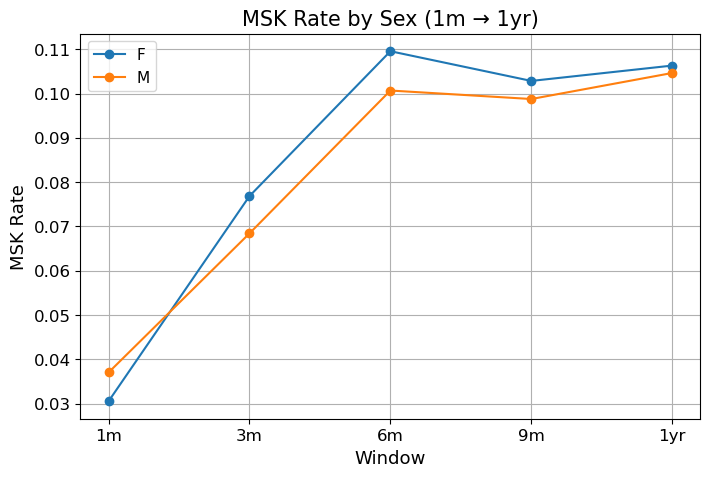

/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/1896251573.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["window", "age_group"])["MSK_Diagnosis"]


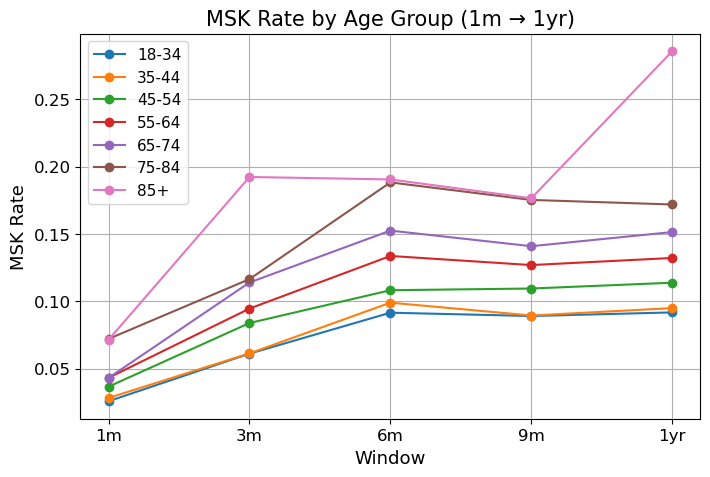

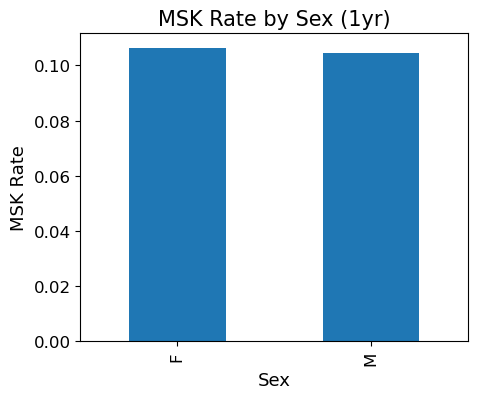

/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/1896251573.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_overall = df_1yr.groupby("age_group")["MSK_Diagnosis"].mean()


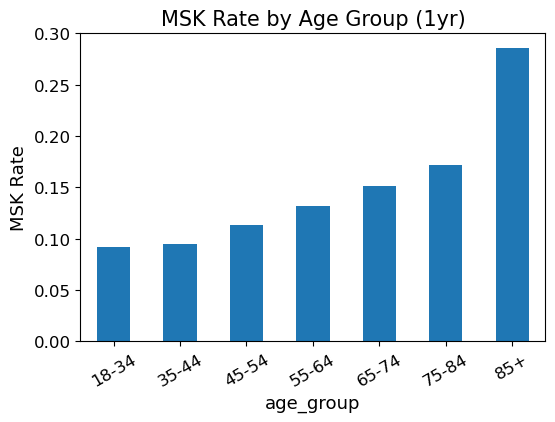

In [305]:

df = pd.read_csv(OUTDIR / "final_analysis_long.csv")

# basic clean
df["MSK_Diagnosis"] = pd.to_numeric(df["MSK_Diagnosis"], errors="coerce").fillna(0).astype(int)
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# keep only 1yr以内
df = df[df["window_days"] <= 365].copy()



bins = [18, 35, 50, 65, 75, 85, 95,200]
labels = ["18-34", "35-44", "45-54", "55-64", "65-74","75-84","85+"]
df["age_group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)


window_order = ["1m", "3m", "6m", "9m", "1yr"]
df["window"] = pd.Categorical(df["window"], categories=window_order, ordered=True)

sex_plot = (
    df.groupby(["window", "Sex"])["MSK_Diagnosis"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8,5))
for sex in sex_plot["Sex"].unique():
    sub = sex_plot[sex_plot["Sex"] == sex]
    plt.plot(sub["window"], sub["MSK_Diagnosis"], marker="o", label=sex)

plt.title("MSK Rate by Sex (1m → 1yr)")
plt.ylabel("MSK Rate")
plt.xlabel("Window")
plt.legend()
plt.grid()
plt.show()
age_plot = (
    df.groupby(["window", "age_group"])["MSK_Diagnosis"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8,5))
for grp in age_plot["age_group"].dropna().unique():
    sub = age_plot[age_plot["age_group"] == grp]
    plt.plot(sub["window"], sub["MSK_Diagnosis"], marker="o", label=str(grp))

plt.title("MSK Rate by Age Group (1m → 1yr)")
plt.ylabel("MSK Rate")
plt.xlabel("Window")
plt.legend()
plt.grid()
plt.show()


df_1yr = df[df["window"] == "1yr"].copy()

# --- Sex
sex_overall = df_1yr.groupby("Sex")["MSK_Diagnosis"].mean()

plt.figure(figsize=(5,4))
sex_overall.plot(kind="bar")
plt.title("MSK Rate by Sex (1yr)")
plt.ylabel("MSK Rate")
plt.show()

# Age group
age_overall = df_1yr.groupby("age_group")["MSK_Diagnosis"].mean()

plt.figure(figsize=(6,4))
age_overall.plot(kind="bar")
plt.title("MSK Rate by Age Group (1yr)")
plt.ylabel("MSK Rate")
plt.xticks(rotation=30)
plt.show()

/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/3456393180.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_plot.groupby(["age_group", "Sex"])


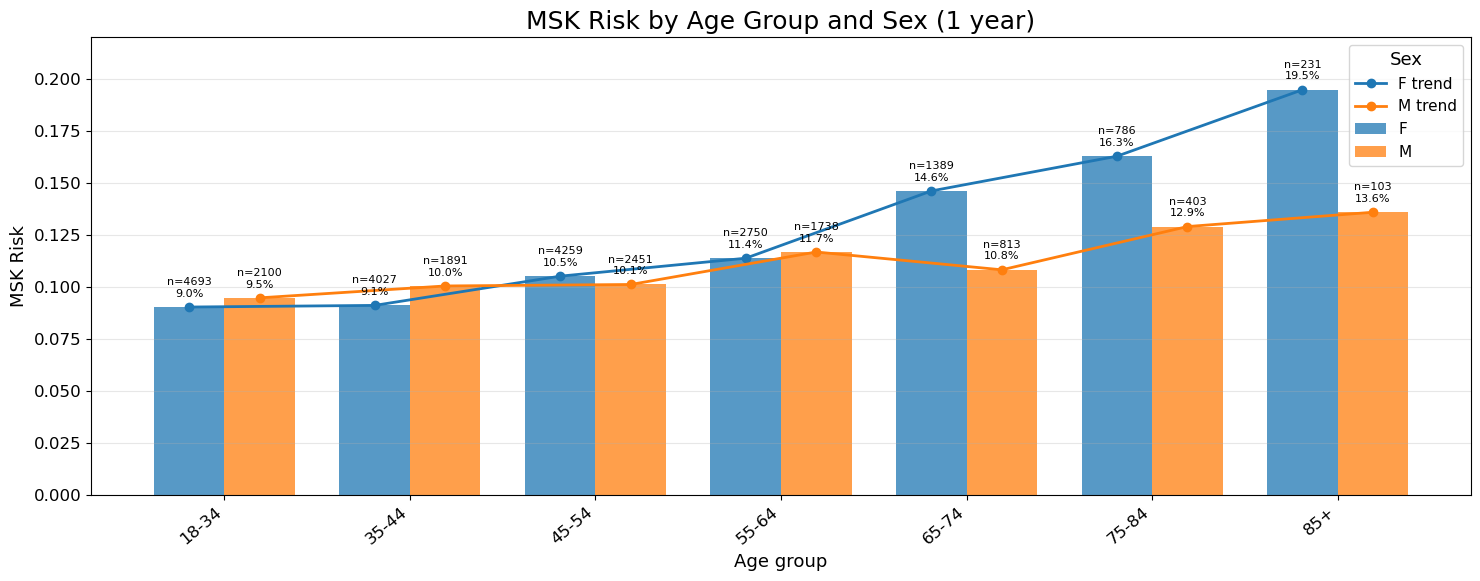

In [306]:

sex_colors = {
    "F": "#1f77b4",   # 蓝
    "M": "#ff7f0e"    # 橙
}


bins = [18, 35, 45, 55, 65, 75, 85,200]
labels = ["18-34", "35-44", "45-54", "55-64", "65-74","75-84","85+"]

df["age_group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    right=False
)
df["age_group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)

target_window = "1yr"
df_plot = df[df["window"] == target_window].copy()

df_plot = df_plot[df_plot["age_group"].notna() & df_plot["Sex"].notna()].copy()

summary = (
    df_plot.groupby(["age_group", "Sex"])
    .agg(
        n=("Patient_ID", "size"),
        msk_cases=("MSK_Diagnosis", "sum"),
        msk_rate=("MSK_Diagnosis", "mean"),
    )
    .reset_index()
)

summary["age_group"] = pd.Categorical(
    summary["age_group"],
    categories=labels,
    ordered=True
)
summary = summary.sort_values(["age_group", "Sex"])

rate_pivot = summary.pivot(index="age_group", columns="Sex", values="msk_rate")
n_pivot = summary.pivot(index="age_group", columns="Sex", values="n")

rate_pivot = rate_pivot.dropna(how="all")
n_pivot = n_pivot.loc[rate_pivot.index]

x = np.arange(len(rate_pivot.index))
width = 0.38

fig, ax = plt.subplots(figsize=(15, 6))

sex_order = [s for s in ["F", "M"] if s in rate_pivot.columns] + \
            [s for s in rate_pivot.columns if s not in ["F", "M"]]

offset_map = {
    sex_order[0]: -width/2 if len(sex_order) > 1 else 0
}
if len(sex_order) > 1:
    offset_map[sex_order[1]] = width/2

# ===== bars（只加 color）=====
for sex in sex_order:
    offset = offset_map.get(sex, 0)
    vals = rate_pivot[sex].fillna(0).values

    ax.bar(
        x + offset,
        vals,
        width=width,
        label=f"{sex}",
        alpha=0.75,
        color=sex_colors.get(sex)
    )

# ===== lines（只加 color）=====
for sex in sex_order:
    offset = offset_map.get(sex, 0)
    vals = rate_pivot[sex].values

    ax.plot(
        x + offset,
        vals,
        marker="o",
        linewidth=2,
        linestyle="-",
        color=sex_colors.get(sex),
        label=f"{sex} trend"
    )

# annotations（完全不动）
for sex in sex_order:
    offset = offset_map.get(sex, 0)

    for i, age_grp in enumerate(rate_pivot.index):
        rate = rate_pivot.loc[age_grp, sex] if sex in rate_pivot.columns else np.nan
        n = n_pivot.loc[age_grp, sex] if sex in n_pivot.columns else np.nan

        if pd.notna(rate) and pd.notna(n) and n > 0:
            ax.text(
                x[i] + offset,
                rate + 0.004,
                f"n={int(n)}\n{rate:.1%}",
                ha="center",
                va="bottom",
                fontsize=8
            )

ax.set_title(f"MSK Risk by Age Group and Sex (1 year)", fontsize=18)
ax.set_xlabel("Age group", fontsize=13)
ax.set_ylabel("MSK Risk", fontsize=13)

ax.set_xticks(x)
ax.set_xticklabels(rate_pivot.index.astype(str), rotation=40, ha="right")
ax.set_ylim(None, 0.22)
ax.legend(title="Sex")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [307]:
results = []

for age in df_plot["age_group"].dropna().unique():
    sub = df_plot[df_plot["age_group"] == age]

    table = pd.crosstab(sub["Sex"], sub["MSK_Diagnosis"])

    if table.shape == (2, 2):  # 确保是2x2
        chi2, p, _, _ = chi2_contingency(table)

        results.append({
            "age_group": age,
            "chi2": chi2,
            "p_value": p
        })

chi_df = pd.DataFrame(results)
print(chi_df)

  age_group      chi2   p_value
0     65-74  6.099130  0.013525
1     55-64  0.066106  0.797093
2     18-34  0.288493  0.591188
3     75-84  2.115617  0.145803
4     45-54  0.227164  0.633634
5     35-44  1.209590  0.271413
6       85+  1.317476  0.251045


/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/3789161986.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["age_group", "Sex"])


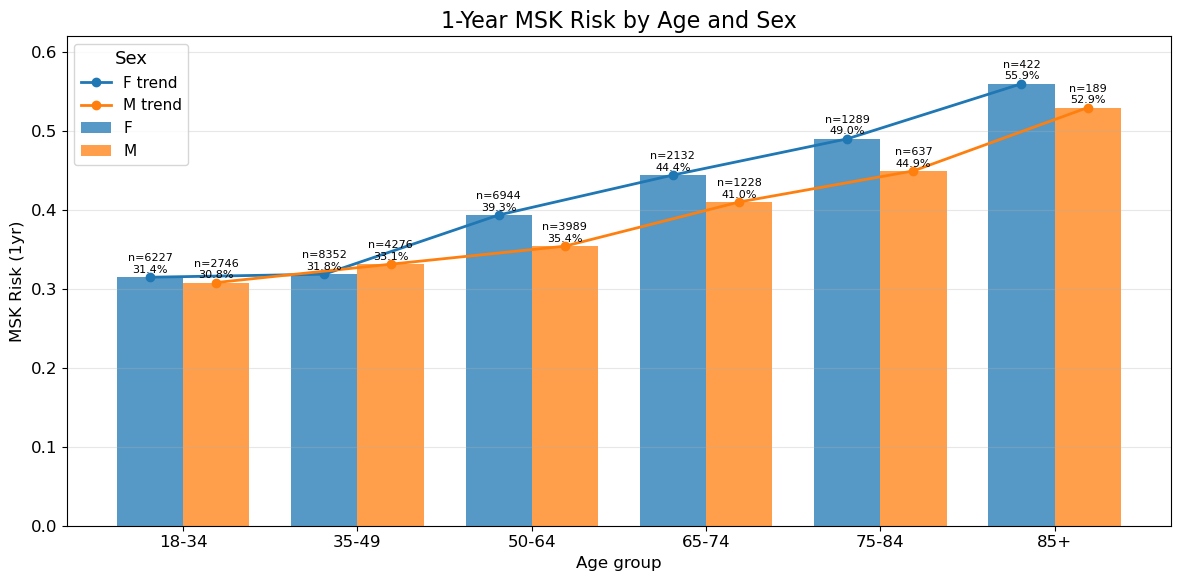

In [308]:
df = pd.read_csv(OUTDIR / "df_1yr_from_long.csv")

df = df.copy()

df["MSK_Diagnosis_1yr"] = pd.to_numeric(df["MSK_Diagnosis_1yr"], errors="coerce").fillna(0).astype(int)
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

bins = [18, 35, 50, 65, 75, 85, 200]
labels = ["18-34", "35-49", "50-64", "65-74", "75-84", "85+"]

df["age_group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)

sex_colors = {
    "F": "#1f77b4",
    "M": "#ff7f0e"
}

summary = (
    df.groupby(["age_group", "Sex"])
    .agg(
        n=("Patient_ID", "size"),
        msk_cases=("MSK_Diagnosis_1yr", "sum"),
        msk_rate=("MSK_Diagnosis_1yr", "mean"),
    )
    .reset_index()
)

summary["age_group"] = pd.Categorical(summary["age_group"], categories=labels, ordered=True)
summary = summary.sort_values(["age_group", "Sex"])

rate_pivot = summary.pivot(index="age_group", columns="Sex", values="msk_rate")
n_pivot = summary.pivot(index="age_group", columns="Sex", values="n")

x = np.arange(len(rate_pivot.index))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 6))

sex_order = ["F", "M"]

offset_map = {
    "F": -width / 2,
    "M": width / 2
}

for sex in sex_order:
    if sex not in rate_pivot.columns:
        continue
    vals = rate_pivot[sex].fillna(0).values
    ax.bar(
        x + offset_map[sex],
        vals,
        width=width,
        label=sex,
        alpha=0.75,
        color=sex_colors[sex]
    )

for sex in sex_order:
    if sex not in rate_pivot.columns:
        continue
    vals = rate_pivot[sex].values
    ax.plot(
        x + offset_map[sex],
        vals,
        marker="o",
        linewidth=2,
        color=sex_colors[sex],
        label=f"{sex} trend"
    )

for sex in sex_order:
    if sex not in rate_pivot.columns:
        continue

    for i, age_grp in enumerate(rate_pivot.index):
        rate = rate_pivot.loc[age_grp, sex]
        n = n_pivot.loc[age_grp, sex]

        if pd.notna(rate) and pd.notna(n) and n > 0:
            ax.text(
                x[i] + offset_map[sex],
                rate + 0.003,
                f"n={int(n)}\n{rate:.1%}",
                ha="center",
                va="bottom",
                fontsize=8
            )

ax.set_title("1-Year MSK Risk by Age and Sex", fontsize=16)
ax.set_xlabel("Age group", fontsize=12)
ax.set_ylabel("MSK Risk (1yr)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(rate_pivot.index.astype(str))
ax.set_ylim(None, rate_pivot.max().max() + 0.06)
ax.legend(title="Sex")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/923350105.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["age_group", "Sex"])


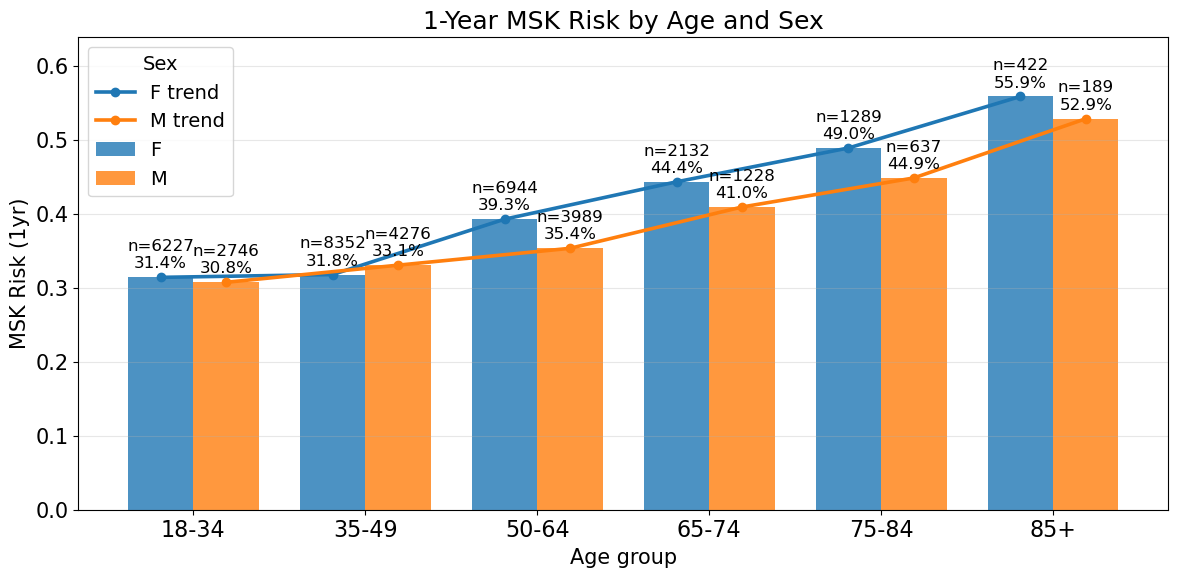

In [309]:
# ===============================
# 全局字体（关键‼️）
# ===============================
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 15,
    "legend.fontsize": 14
})


df = pd.read_csv(OUTDIR / "df_1yr_from_long.csv")
df = df.copy()

df["MSK_Diagnosis_1yr"] = pd.to_numeric(df["MSK_Diagnosis_1yr"], errors="coerce").fillna(0).astype(int)
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

bins = [18, 35, 50, 65, 75, 85, 200]
labels = ["18-34", "35-49", "50-64", "65-74", "75-84", "85+"]

df["age_group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)

sex_colors = {
    "F": "#1f77b4",
    "M": "#ff7f0e"
}

summary = (
    df.groupby(["age_group", "Sex"])
    .agg(
        n=("Patient_ID", "size"),
        msk_cases=("MSK_Diagnosis_1yr", "sum"),
        msk_rate=("MSK_Diagnosis_1yr", "mean"),
    )
    .reset_index()
)

summary["age_group"] = pd.Categorical(summary["age_group"], categories=labels, ordered=True)
summary = summary.sort_values(["age_group", "Sex"])

rate_pivot = summary.pivot(index="age_group", columns="Sex", values="msk_rate")
n_pivot = summary.pivot(index="age_group", columns="Sex", values="n")

x = np.arange(len(rate_pivot.index))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 6))

sex_order = ["F", "M"]

offset_map = {
    "F": -width / 2,
    "M": width / 2
}

# ===============================
# BAR
# ===============================
for sex in sex_order:
    if sex not in rate_pivot.columns:
        continue
    vals = rate_pivot[sex].fillna(0).values
    ax.bar(
        x + offset_map[sex],
        vals,
        width=width,
        label=sex,
        alpha=0.8,
        color=sex_colors[sex]
    )

# ===============================
# LINE
# ===============================
for sex in sex_order:
    if sex not in rate_pivot.columns:
        continue
    vals = rate_pivot[sex].values
    ax.plot(
        x + offset_map[sex],
        vals,
        marker="o",
        linewidth=2.6,   # 稍微加粗
        color=sex_colors[sex],
        label=f"{sex} trend"
    )

# ===============================
# TEXT（放大‼️）
# ===============================
for sex in sex_order:
    if sex not in rate_pivot.columns:
        continue

    for i, age_grp in enumerate(rate_pivot.index):
        rate = rate_pivot.loc[age_grp, sex]
        n = n_pivot.loc[age_grp, sex]

        if pd.notna(rate) and pd.notna(n) and n > 0:
            ax.text(
                x[i] + offset_map[sex],
                rate + 0.008,   # 往上移一点（避免挤）
                f"n={int(n)}\n{rate:.1%}",
                ha="center",
                va="bottom",
                fontsize=12     # ⭐ 原来8 → 11（关键）
            )

# ===============================
# AXES
# ===============================
ax.set_title("1-Year MSK Risk by Age and Sex", fontsize=18)
ax.set_xlabel("Age group", fontsize=15)
ax.set_ylabel("MSK Risk (1yr)", fontsize=15)

ax.set_xticks(x)
ax.set_xticklabels(rate_pivot.index.astype(str))

# ⭐ 上限稍微多一点（防止挤）
ax.set_ylim(None, rate_pivot.max().max() + 0.08)

# ===============================
# LEGEND（更清晰）
# ===============================
ax.legend(title="Sex", title_fontsize=14)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# test

In [310]:

# contingency table
table = pd.crosstab(df["Sex"], df["MSK_Diagnosis_1yr"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square test (Sex)")
print("chi2:", chi2)
print("p-value:", p)
print("\nTable:")
print(table)

Chi-square test (Sex)
chi2: 5.402322644215533
p-value: 0.020109972082809763

Table:
MSK_Diagnosis_1yr      0     1
Sex                           
F                  16207  9159
M                   8505  4560


## correlation matrix

mental_dummies: ['mental_acute', 'mental_both', 'mental_symptom']

=== removed constant columns ===
set()

before dropna: (38431, 17)
after dropna: (38431, 17)

final columns: ['MSK_Diagnosis', 'Age', 'Sex_num', 'Pre_existing_condition_count', 'Multimorbidity_count', 'Mental_Diagnosis_count', 'mental_acute', 'mental_both', 'mental_symptom', 'mental_antidepressant', 'mental_antipsychotic', 'mental_anti_anxiety', 'mental_hypnotic', 'pain_nsaid', 'pain_acetaminophen', 'pain_muscle_relaxant', 'pain_opioid']


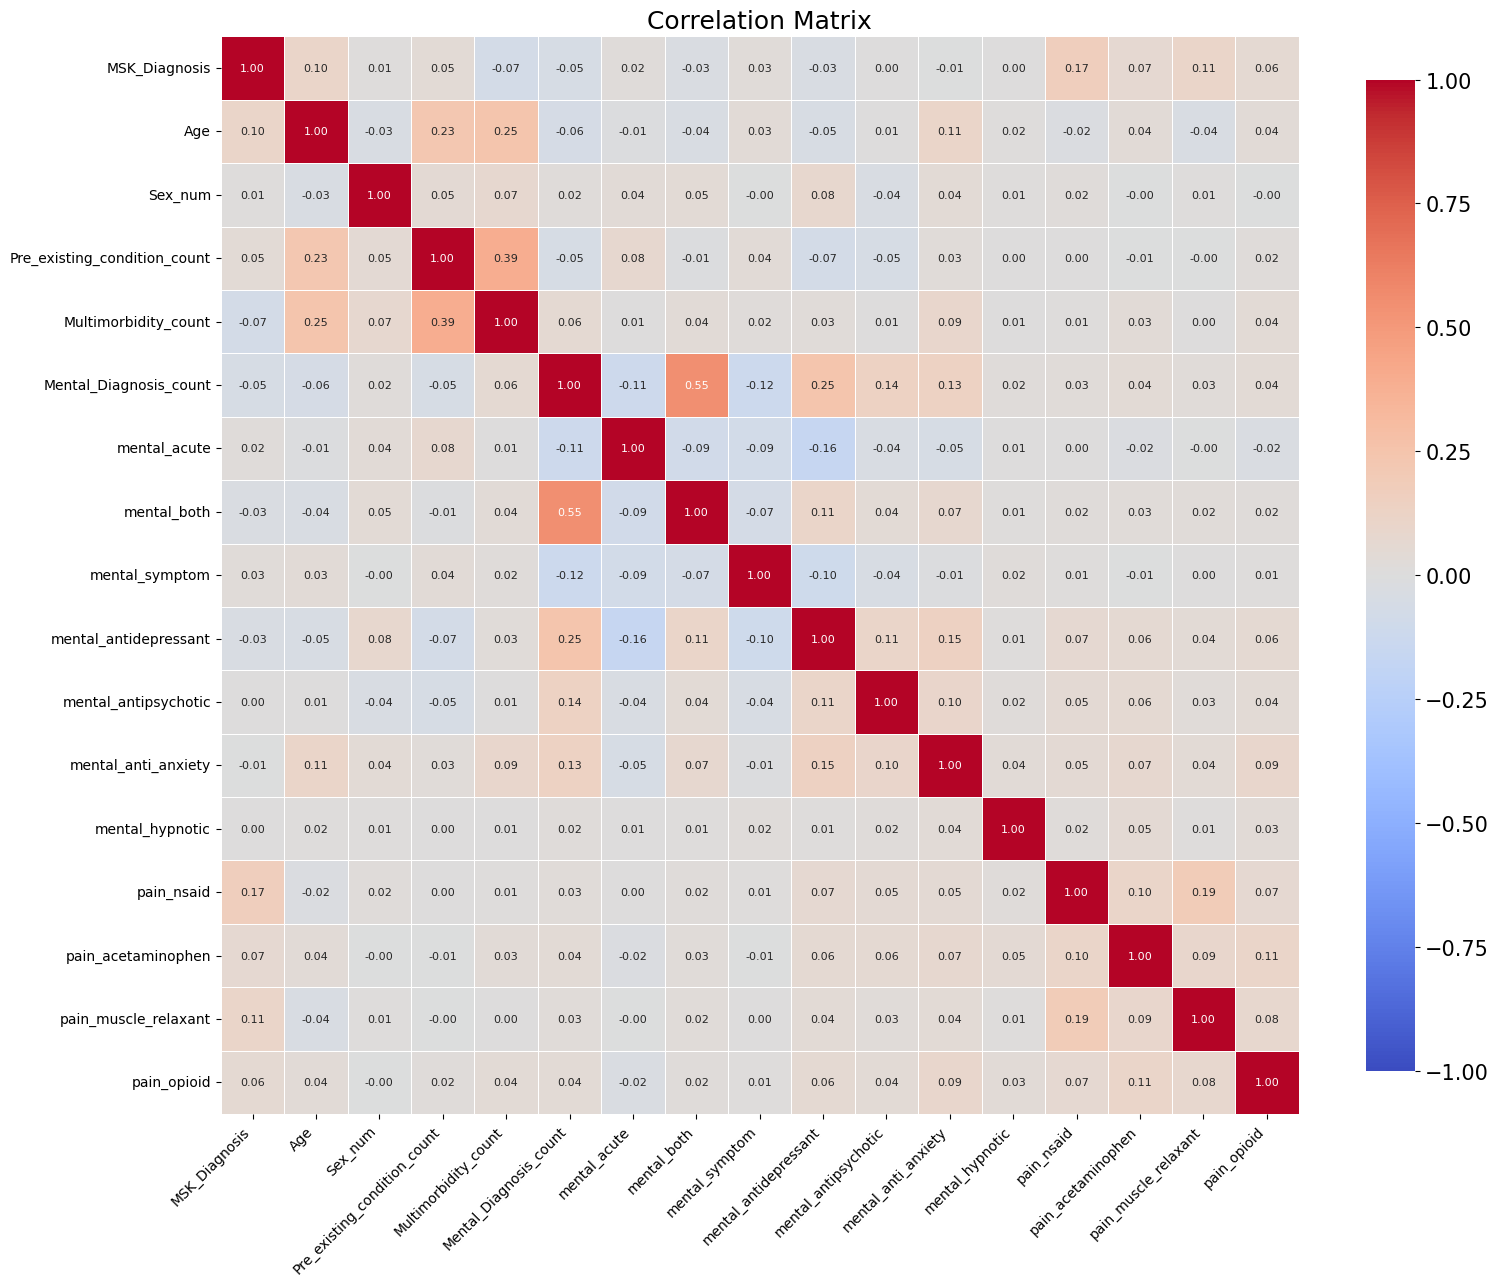

In [311]:
df_corr = df.copy()

# Sex
df_corr["Sex_num"] = df_corr["Sex"].map({"M": 0, "F": 1})

# mental group
df_corr["Overall_Mental_group"] = pd.Categorical(
    df_corr["Overall_Mental_group"],
    categories=["chronic", "acute", "both", "symptom"],
    ordered=True
)

mental_dummies = pd.get_dummies(
    df_corr["Overall_Mental_group"],
    prefix="mental",
    drop_first=True
)

df_corr = pd.concat([df_corr, mental_dummies], axis=1)

print("mental_dummies:", mental_dummies.columns.tolist())

corr_vars = [
    "MSK_Diagnosis",
    "Age",
    "Sex_num",
    "Pre_existing_condition_count",
    "Multimorbidity_count",
    "Mental_Diagnosis_count",
    "mental_acute",
    "mental_both",
    "mental_symptom",
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]


df_corr = df_corr[corr_vars].copy()
nunique = df_corr.nunique()
valid_cols = nunique[nunique > 1].index.tolist()

print("\n=== removed constant columns ===")
print(set(df_corr.columns) - set(valid_cols))

df_corr = df_corr[valid_cols]

print("\nbefore dropna:", df_corr.shape)
df_corr = df_corr.dropna()
print("after dropna:", df_corr.shape)

corr_matrix = df_corr.corr(method="pearson")

print("\nfinal columns:", df_corr.columns.tolist())

plt.figure(figsize=(16, 14))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Matrix", fontsize=18)

plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

In [312]:
print(df_corr.dtypes)
print("\nMissing values:\n", df_corr.isna().sum())
print("\nUnique values:\n")
for col in df_corr.columns:
    print(col, df_corr[col].dropna().unique()[:10], "n_unique =", df_corr[col].nunique(dropna=True))

MSK_Diagnosis                     int64
Age                             float64
Sex_num                           int64
Pre_existing_condition_count      int64
Multimorbidity_count            float64
Mental_Diagnosis_count            int64
mental_acute                       bool
mental_both                        bool
mental_symptom                     bool
mental_antidepressant             int64
mental_antipsychotic              int64
mental_anti_anxiety               int64
mental_hypnotic                   int64
pain_nsaid                        int64
pain_acetaminophen                int64
pain_muscle_relaxant              int64
pain_opioid                       int64
dtype: object

Missing values:
 MSK_Diagnosis                   0
Age                             0
Sex_num                         0
Pre_existing_condition_count    0
Multimorbidity_count            0
Mental_Diagnosis_count          0
mental_acute                    0
mental_both                     0
mental_symptom  

## demo KM plot（mental group and sex）

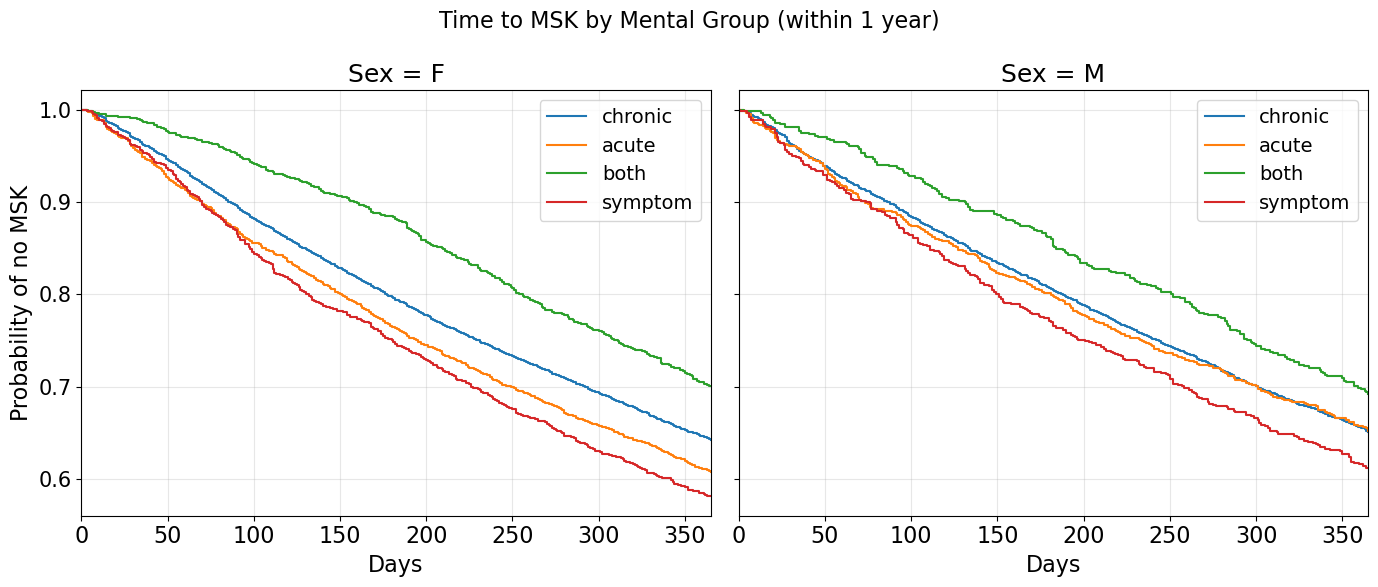

In [313]:

df = pd.read_csv(OUTDIR / "df_1yr_from_long.csv")

df = df.copy()
df["time_to_msk_days"] = pd.to_numeric(df["time_to_msk_days"], errors="coerce")

# keep only rows with needed variables
df = df[
    df["Sex"].isin(["F", "M"]) &
    df["Overall_Mental_group"].isin(["chronic", "acute", "both", "symptom"])
].copy()

df["event_1yr"] = (
    df["time_to_msk_days"].notna() &
    (df["time_to_msk_days"] <= 365)
).astype(int)

df["time_1yr"] = np.where(
    df["event_1yr"] == 1,
    df["time_to_msk_days"],
    365
)

mental_order = ["chronic", "acute", "both", "symptom"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, sex in zip(axes, ["F", "M"]):
    sub_sex = df[df["Sex"] == sex].copy()
    kmf = KaplanMeierFitter()

    for group in mental_order:
        sub = sub_sex[sub_sex["Overall_Mental_group"] == group].copy()
        if sub.empty:
            continue

        kmf.fit(
            durations=sub["time_1yr"],
            event_observed=sub["event_1yr"],
            label=group
        )
        kmf.plot_survival_function(ax=ax, ci_show=False)

    ax.set_title(f"Sex = {sex}")
    ax.set_xlabel("Days")
    ax.set_xlim(0, 365)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Probability of no MSK")
fig.suptitle("Time to MSK by Mental Group (within 1 year)", fontsize=16)
plt.tight_layout()
plt.show()

In [314]:


results = multivariate_logrank_test(
    df["time_1yr"],
    df["Overall_Mental_group"],
    df["event_1yr"]
)

print("Overall log-rank p-value:", results.p_value)

Overall log-rank p-value: 3.184805800556084e-18


In [315]:
for sex in ["F", "M"]:
    sub = df[df["Sex"] == sex].copy()

    results = multivariate_logrank_test(
        sub["time_1yr"],
        sub["Overall_Mental_group"],
        sub["event_1yr"]
    )

    print(f"\nLog-rank p-value (Sex = {sex}):", results.p_value)


Log-rank p-value (Sex = F): 4.2469255978368826e-17

Log-rank p-value (Sex = M): 0.006649333526789524


In [316]:
from lifelines.statistics import multivariate_logrank_test

print("\n=== Overall log-rank test by Sex ===")

for sex in ["F", "M"]:
    sub = df[df["Sex"] == sex].copy()

    result = multivariate_logrank_test(
        sub["time_1yr"],
        sub["Overall_Mental_group"],
        sub["event_1yr"]
    )

    print(f"\nSex = {sex}")
    print(f"Chi-square = {result.test_statistic:.3f}")
    print(f"p-value   = {result.p_value:.4e}")


=== Overall log-rank test by Sex ===

Sex = F
Chi-square = 79.342
p-value   = 4.2469e-17

Sex = M
Chi-square = 12.225
p-value   = 6.6493e-03


In [317]:
from lifelines.statistics import logrank_test
from itertools import combinations

print("\n=== Pairwise log-rank test ===")

for sex in ["F", "M"]:
    print(f"\nSex = {sex}")
    sub_sex = df[df["Sex"] == sex].copy()

    groups = sub_sex["Overall_Mental_group"].unique()

    for g1, g2 in combinations(groups, 2):
        sub1 = sub_sex[sub_sex["Overall_Mental_group"] == g1]
        sub2 = sub_sex[sub_sex["Overall_Mental_group"] == g2]

        result = logrank_test(
            sub1["time_1yr"], sub2["time_1yr"],
            event_observed_A=sub1["event_1yr"],
            event_observed_B=sub2["event_1yr"]
        )

        print(f"{g1} vs {g2}: p = {result.p_value:.4f}")


=== Pairwise log-rank test ===

Sex = F
chronic vs both: p = 0.0000
chronic vs acute: p = 0.0001
chronic vs symptom: p = 0.0000
both vs acute: p = 0.0000
both vs symptom: p = 0.0000
acute vs symptom: p = 0.0959

Sex = M
chronic vs acute: p = 0.9203
chronic vs both: p = 0.0160
chronic vs symptom: p = 0.0174
acute vs both: p = 0.0361
acute vs symptom: p = 0.0734
both vs symptom: p = 0.0004


## mental group and sex model

Age and female sex were significantly associated with increased 1-year MSK risk. While mental group alone was not significantly associated with MSK risk, a significant interaction was observed for the acute group, indicating a stronger effect in females.

## medication

## acute vs chronic

## medication demo

In [318]:


df = pd.read_csv(OUTDIR / "df_1yr_from_long.csv").copy()

# basic clean
df["MSK_Diagnosis_1yr"] = pd.to_numeric(df["MSK_Diagnosis_1yr"], errors="coerce").fillna(0).astype(int)

med_cols = [
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]

med_cols = [c for c in med_cols if c in df.columns]

for col in med_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

# overall
overall_demo = pd.DataFrame({
    "medication": med_cols,
    "n": [df[c].sum() for c in med_cols],
    "pct": [df[c].mean() * 100 for c in med_cols]
}).sort_values("pct", ascending=False)

print(overall_demo)

              medication      n        pct
0  mental_antidepressant  15772  41.039786
2    mental_anti_anxiety   8211  21.365564
4             pain_nsaid   4779  12.435274
5     pain_acetaminophen   1898   4.938721
7            pain_opioid   1537   3.999376
1   mental_antipsychotic   1520   3.955140
6   pain_muscle_relaxant   1194   3.106867
3        mental_hypnotic    328   0.853478


In [319]:
sex_rows = []

for sex in sorted(df["Sex"].dropna().unique()):
    sub = df[df["Sex"] == sex].copy()
    for col in med_cols:
        sex_rows.append({
            "Sex": sex,
            "medication": col,
            "n": sub[col].sum(),
            "pct": sub[col].mean() * 100
        })

sex_demo_long = pd.DataFrame(sex_rows)
print(sex_demo_long.sort_values(["medication", "Sex"]))

   Sex             medication      n        pct
2    F    mental_anti_anxiety   5744  22.644485
10   M    mental_anti_anxiety   2467  18.882511
0    F  mental_antidepressant  11140  43.917054
8    M  mental_antidepressant   4632  35.453502
1    F   mental_antipsychotic    874   3.445557
9    M   mental_antipsychotic    646   4.944508
3    F        mental_hypnotic    233   0.918552
11   M        mental_hypnotic     95   0.727134
5    F     pain_acetaminophen   1244   4.904202
13   M     pain_acetaminophen    654   5.005741
6    F   pain_muscle_relaxant    829   3.268154
14   M   pain_muscle_relaxant    365   2.793724
4    F             pain_nsaid   3257  12.840022
12   M             pain_nsaid   1522  11.649445
7    F            pain_opioid   1003   3.954112
15   M            pain_opioid    534   4.087256


In [320]:
mental_demo_rows = []

for grp in ["chronic", "acute", "both", "symptom"]:
    sub = df[df["Overall_Mental_group"] == grp].copy()
    if sub.empty:
        continue

    for col in med_cols:
        mental_demo_rows.append({
            "mental_group": grp,
            "medication": col,
            "n": sub[col].sum(),
            "pct": sub[col].mean() * 100
        })

mental_demo = pd.DataFrame(mental_demo_rows)
print(mental_demo.sort_values(["medication", "mental_group"]))

   mental_group             medication      n        pct
10        acute    mental_anti_anxiety    613  15.113412
18         both    mental_anti_anxiety    814  33.008921
2       chronic    mental_anti_anxiety   6349  21.408821
26      symptom    mental_anti_anxiety    435  19.307590
8         acute  mental_antidepressant    733  18.071992
16         both  mental_antidepressant   1514  61.394972
0       chronic  mental_antidepressant  13063  44.048422
24      symptom  mental_antidepressant    462  20.505992
9         acute   mental_antipsychotic     72   1.775148
17         both   mental_antipsychotic    175   7.096513
1       chronic   mental_antipsychotic   1256   4.235231
25      symptom   mental_antipsychotic     17   0.754549
11        acute        mental_hypnotic     41   1.010848
19         both        mental_hypnotic     33   1.338200
3       chronic        mental_hypnotic    219   0.738468
27      symptom        mental_hypnotic     35   1.553484
13        acute     pain_acetam

In [321]:
msk_demo_rows = []

for outcome in [0, 1]:
    sub = df[df["MSK_Diagnosis_1yr"] == outcome].copy()

    for col in med_cols:
        msk_demo_rows.append({
            "MSK_Diagnosis_1yr": outcome,
            "medication": col,
            "n": sub[col].sum(),
            "pct": sub[col].mean() * 100
        })

msk_demo = pd.DataFrame(msk_demo_rows)
print(msk_demo.sort_values(["medication", "MSK_Diagnosis_1yr"]))

    MSK_Diagnosis_1yr             medication      n        pct
2                   0    mental_anti_anxiety   5327  21.556329
10                  1    mental_anti_anxiety   2884  21.021940
0                   0  mental_antidepressant  10440  42.246682
8                   1  mental_antidepressant   5332  38.865807
1                   0   mental_antipsychotic    968   3.917125
9                   1   mental_antipsychotic    552   4.023617
3                   0        mental_hypnotic    205   0.829556
11                  1        mental_hypnotic    123   0.896567
5                   0     pain_acetaminophen    960   3.884752
13                  1     pain_acetaminophen    938   6.837233
6                   0   pain_muscle_relaxant    428   1.731952
14                  1   pain_muscle_relaxant    766   5.583497
4                   0             pain_nsaid   2050   8.295565
12                  1             pain_nsaid   2729  19.892120
7                   0            pain_opioid    779   3

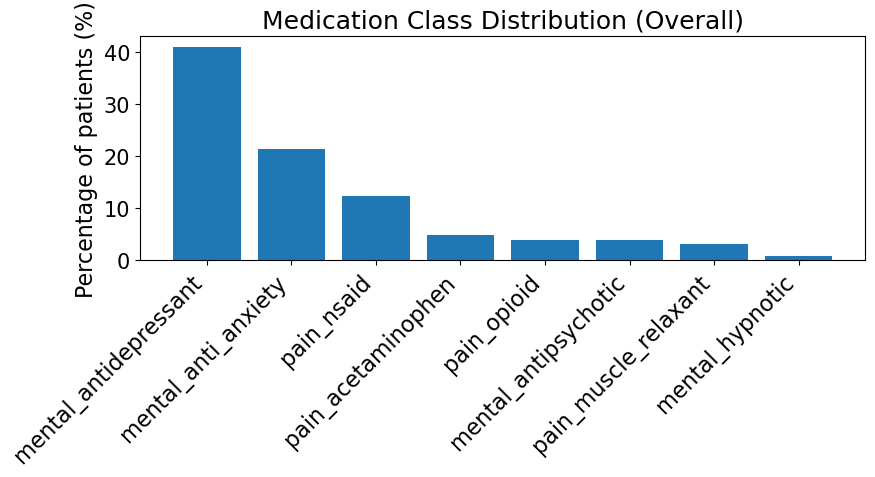

In [322]:

plot_df = overall_demo.copy()

plt.figure(figsize=(9, 5))
plt.bar(plot_df["medication"], plot_df["pct"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Percentage of patients (%)")
plt.title("Medication Class Distribution (Overall)")
plt.tight_layout()
plt.show()

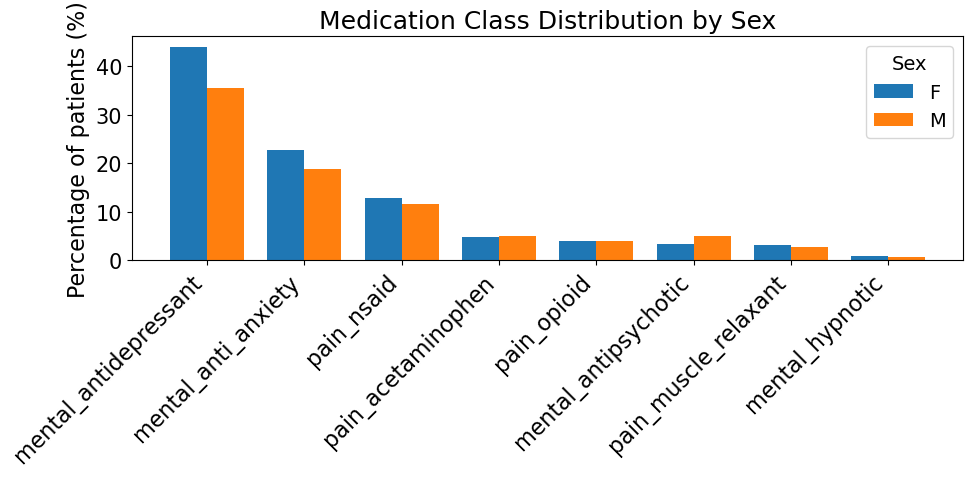

In [323]:
plot_df = sex_demo_long.copy()

med_order = overall_demo["medication"].tolist()
sex_order = ["F", "M"]

x = np.arange(len(med_order))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))

for i, sex in enumerate(sex_order):
    sub = plot_df[plot_df["Sex"] == sex].copy()
    sub = sub.set_index("medication").reindex(med_order).reset_index()

    ax.bar(
        x + (i - 0.5) * width,
        sub["pct"],
        width=width,
        label=sex
    )

ax.set_xticks(x)
ax.set_xticklabels(med_order, rotation=45, ha="right")
ax.set_ylabel("Percentage of patients (%)")
ax.set_title("Medication Class Distribution by Sex")
ax.legend(title="Sex")
plt.tight_layout()
plt.show()

In [324]:
def summarize_binary(df, cols, group_col=None):
    rows = []

    if group_col is None:
        for col in cols:
            rows.append({
                "variable": col,
                "group": "Overall",
                "n": int(df[col].sum()),
                "pct": df[col].mean() * 100
            })
    else:
        for g in sorted(df[group_col].dropna().unique()):
            sub = df[df[group_col] == g]
            for col in cols:
                rows.append({
                    "variable": col,
                    "group": g,
                    "n": int(sub[col].sum()),
                    "pct": sub[col].mean() * 100
                })

    return pd.DataFrame(rows)

table1_med = summarize_binary(df, med_cols, group_col="MSK_Diagnosis_1yr")
print(table1_med)

                 variable  group      n        pct
0   mental_antidepressant      0  10440  42.246682
1    mental_antipsychotic      0    968   3.917125
2     mental_anti_anxiety      0   5327  21.556329
3         mental_hypnotic      0    205   0.829556
4              pain_nsaid      0   2050   8.295565
5      pain_acetaminophen      0    960   3.884752
6    pain_muscle_relaxant      0    428   1.731952
7             pain_opioid      0    779   3.152315
8   mental_antidepressant      1   5332  38.865807
9    mental_antipsychotic      1    552   4.023617
10    mental_anti_anxiety      1   2884  21.021940
11        mental_hypnotic      1    123   0.896567
12             pain_nsaid      1   2729  19.892120
13     pain_acetaminophen      1    938   6.837233
14   pain_muscle_relaxant      1    766   5.583497
15            pain_opioid      1    758   5.525184


In [325]:
mental_cols = [
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",
]

pain_cols = [
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]

# any use（0/1）
df["any_mental_med"] = df[mental_cols].max(axis=1)
df["any_pain_med"] = df[pain_cols].max(axis=1)

In [326]:
overall_demo = pd.DataFrame({
    "group": ["Mental meds", "Pain meds"],
    "n": [
        df["any_mental_med"].sum(),
        df["any_pain_med"].sum()
    ],
    "pct": [
        df["any_mental_med"].mean() * 100,
        df["any_pain_med"].mean() * 100
    ]
})

print(overall_demo)

         group      n        pct
0  Mental meds  19941  51.887799
1    Pain meds   7622  19.832947


In [327]:
rows = []

for outcome in [0, 1]:
    sub = df[df["MSK_Diagnosis_1yr"] == outcome]

    rows.append({
        "MSK": outcome,
        "type": "Mental meds",
        "pct": sub["any_mental_med"].mean() * 100
    })
    rows.append({
        "MSK": outcome,
        "type": "Pain meds",
        "pct": sub["any_pain_med"].mean() * 100
    })

msk_demo = pd.DataFrame(rows)
print(msk_demo)

   MSK         type        pct
0    0  Mental meds  52.723373
1    0    Pain meds  13.936549
2    1  Mental meds  50.382681
3    1    Pain meds  30.454115


In [328]:
rows = []

for grp in ["chronic", "acute", "both", "symptom"]:
    sub = df[df["Overall_Mental_group"] == grp]

    rows.append({
        "mental_group": grp,
        "type": "Mental meds",
        "pct": sub["any_mental_med"].mean() * 100
    })
    rows.append({
        "mental_group": grp,
        "type": "Pain meds",
        "pct": sub["any_pain_med"].mean() * 100
    })

mental_demo = pd.DataFrame(rows)
print(mental_demo)

  mental_group         type        pct
0      chronic  Mental meds  54.376855
1      chronic    Pain meds  19.422714
2        acute  Mental meds  29.659763
3        acute    Pain meds  18.367850
4         both  Mental meds  72.668289
5         both    Pain meds  24.898621
6      symptom  Mental meds  36.395917
7      symptom    Pain meds  22.325788


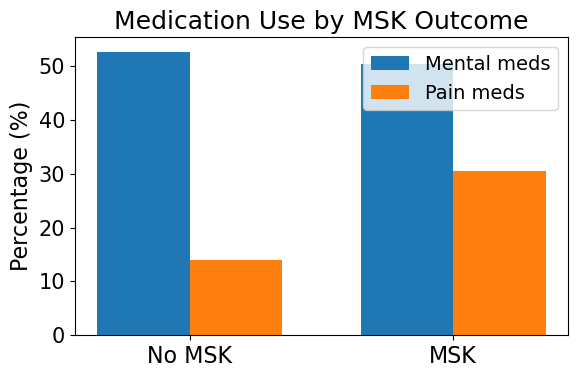

In [329]:

plot_df = msk_demo.copy()

x = np.arange(2)  # MSK 0 / 1
width = 0.35

fig, ax = plt.subplots(figsize=(6, 4))

for i, med_type in enumerate(["Mental meds", "Pain meds"]):
    sub = plot_df[plot_df["type"] == med_type]

    ax.bar(
        x + (i - 0.5) * width,
        sub["pct"],
        width=width,
        label=med_type
    )

ax.set_xticks(x)
ax.set_xticklabels(["No MSK", "MSK"])
ax.set_ylabel("Percentage (%)")
ax.set_title("Medication Use by MSK Outcome")
ax.legend()

plt.tight_layout()
plt.show()

In [330]:
df["med_group"] = "None"

df.loc[(df["any_mental_med"]==1) & (df["any_pain_med"]==0), "med_group"] = "Mental only"
df.loc[(df["any_mental_med"]==0) & (df["any_pain_med"]==1), "med_group"] = "Pain only"
df.loc[(df["any_mental_med"]==1) & (df["any_pain_med"]==1), "med_group"] = "Both"

In [331]:
df.groupby("med_group")["MSK_Diagnosis_1yr"].mean()

med_group
Both           0.521007
Mental only    0.291218
None           0.327507
Pain only      0.594527
Name: MSK_Diagnosis_1yr, dtype: float64

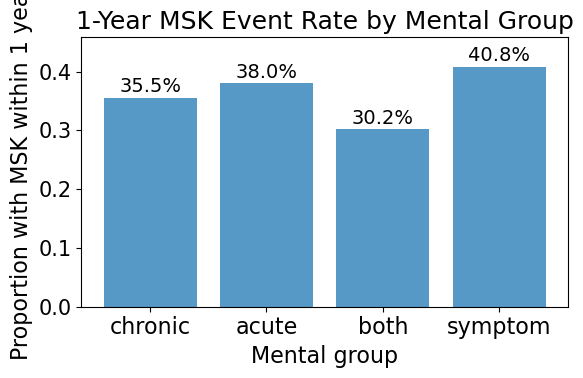

In [332]:
# MSK rate
plot_df = (
    df.groupby("Overall_Mental_group")["MSK_Diagnosis_1yr"]
    .mean()
    .reindex(["chronic", "acute", "both", "symptom"])
)

plt.figure(figsize=(6,4))

bars = plt.bar(
    plot_df.index,
    plot_df.values,
    color="#1f77b4",   # 统一蓝色
    alpha=0.75
)

# label（建议用百分比更直观）
for i, v in enumerate(plot_df.values):
    plt.text(i, v + 0.01, f"{v*100:.1f}%", ha="center")

plt.ylabel("Proportion with MSK within 1 year")
plt.xlabel("Mental group")
plt.title("1-Year MSK Event Rate by Mental Group")

# 上限留一点空间
plt.ylim(None, plot_df.max() + 0.05)

plt.tight_layout()
plt.show()

In [333]:
cont_table = pd.crosstab(
    df["Overall_Mental_group"],
    df["MSK_Diagnosis_1yr"]
)

print(cont_table)

chi2, p, dof, expected = chi2_contingency(cont_table)

print(f"Chi-square = {chi2:.3f}")
print(f"p-value    = {p:.4e}")
print(f"dof        = {dof}")

MSK_Diagnosis_1yr         0      1
Overall_Mental_group              
acute                  2515   1541
both                   1722    744
chronic               19142  10514
symptom                1333    920
Chi-square = 68.803
p-value    = 7.7027e-15
dof        = 3


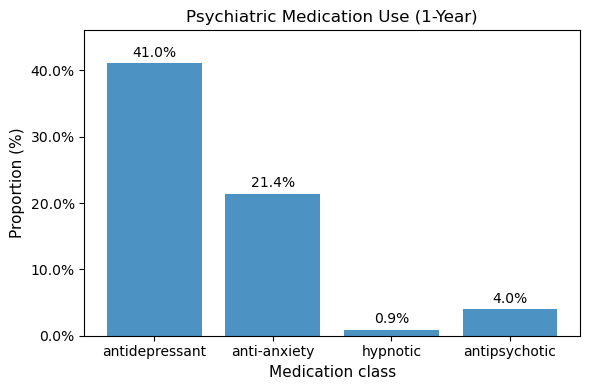

In [334]:
plt.rcParams.update({
    "font.size": 10,        # 全局字体
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

mental_cols = [
    "mental_antidepressant",
    "mental_anti_anxiety",
    "mental_hypnotic",
    "mental_antipsychotic",
]

plot_vals = [df[c].mean() for c in mental_cols]  
labels = ["antidepressant", "anti-anxiety", "hypnotic", "antipsychotic"]

plt.figure(figsize=(6,4))

bars = plt.bar(
    labels,
    plot_vals,
    color="#1f77b4",   
    alpha=0.8
)


for i, v in enumerate(plot_vals):
    plt.text(i, v + 0.01, f"{v*100:.1f}%", ha="center")

plt.ylabel("Proportion (%)")
plt.xlabel("Medication class")
plt.title("Psychiatric Medication Use (1-Year)")

plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.ylim(None, max(plot_vals) + 0.05)

plt.tight_layout()
plt.show()

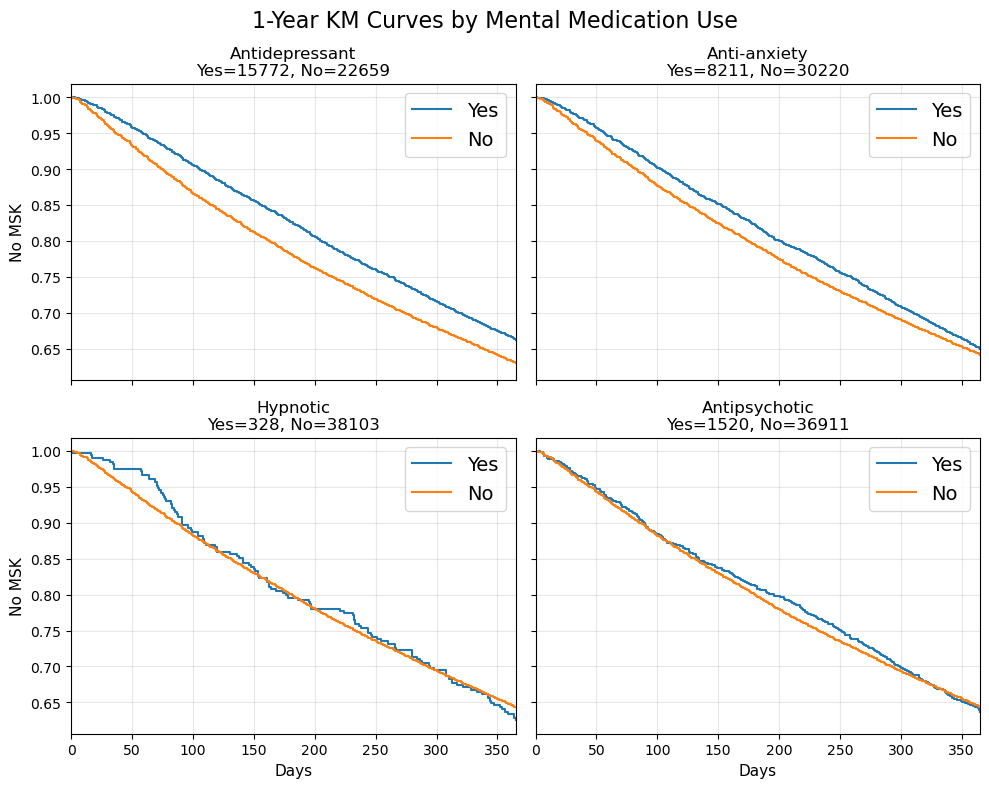

In [335]:

df = df.copy()
df["time_to_msk_days"] = pd.to_numeric(df["time_to_msk_days"], errors="coerce")

df["event_1yr"] = (
    df["time_to_msk_days"].notna() &
    (df["time_to_msk_days"] <= 365)
).astype(int)

df["time_1yr"] = np.where(
    df["event_1yr"] == 1,
    df["time_to_msk_days"],
    365
)

mental_cols = [
    "mental_antidepressant",
    "mental_anti_anxiety",
    "mental_hypnotic",
    "mental_antipsychotic",
]

# make sure 0/1
for col in mental_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

# prettier titles
title_map = {
    "mental_antidepressant": "Antidepressant",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",
    "mental_antipsychotic": "Antipsychotic",
}


fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, col in zip(axes, mental_cols):
    kmf = KaplanMeierFitter()

    for val, label in [(1, "Yes"), (0, "No")]:
        sub = df[df[col] == val].copy()
        if sub.empty:
            continue

        kmf.fit(
            durations=sub["time_1yr"],
            event_observed=sub["event_1yr"],
            label=label
        )
        kmf.plot_survival_function(ax=ax, ci_show=False)

    n_yes = int((df[col] == 1).sum())
    n_no = int((df[col] == 0).sum())

    ax.set_title(f"{title_map[col]}\nYes={n_yes}, No={n_no}")
    ax.set_xlabel("Days")
    ax.set_ylabel("No MSK")
    ax.set_xlim(0, 365)
    ax.grid(alpha=0.3)

fig.suptitle("1-Year KM Curves by Mental Medication Use", fontsize=16)
plt.tight_layout()
plt.show()

In [336]:


for col in mental_cols:
    yes = df[df[col] == 1].copy()
    no = df[df[col] == 0].copy()

    result = logrank_test(
        yes["time_1yr"], no["time_1yr"],
        event_observed_A=yes["event_1yr"],
        event_observed_B=no["event_1yr"]
    )

    print(f"{col}: p = {result.p_value:.4g}")

mental_antidepressant: p = 1.486e-14
mental_anti_anxiety: p = 0.02584
mental_hypnotic: p = 0.6564
mental_antipsychotic: p = 0.8331


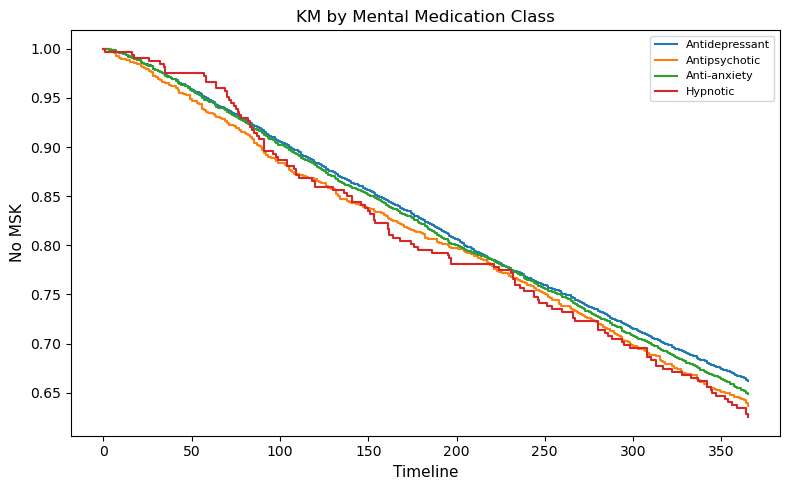

In [337]:

kmf = KaplanMeierFitter()

med_vars = [
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic"
]

labels = {
    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic"
}

plt.figure(figsize=(8, 5))

for med in med_vars:
    sub = df[df[med] == 1].copy()

    if len(sub) == 0:
        print(f"Skip {med}: no patients")
        continue

    kmf.fit(
        durations=sub["time_1yr"],
        event_observed=sub["event_1yr"],
        label=labels[med]
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("KM by Mental Medication Class")
plt.xlabel("Timeline")
plt.ylabel("No MSK")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

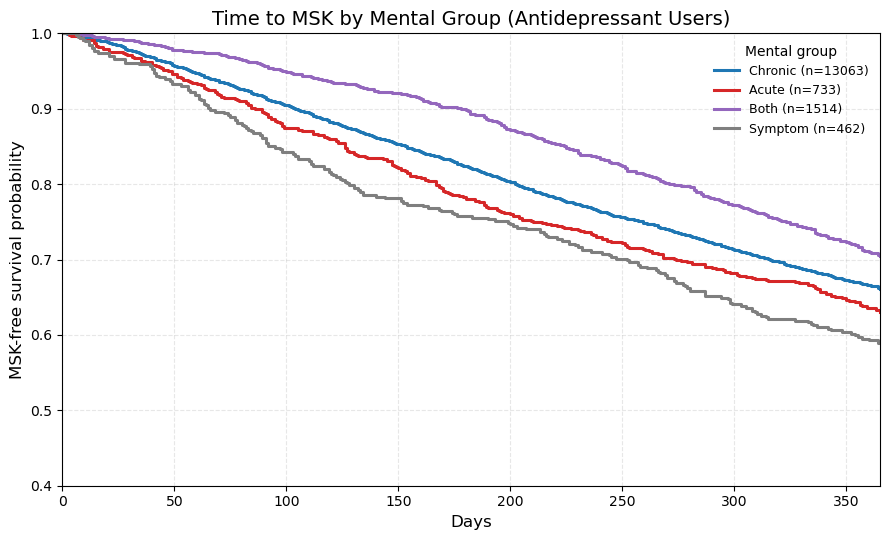

In [338]:

kmf = KaplanMeierFitter()

colors = {
    "chronic": "#1f77b4",  
    "acute": "#d62728",     
    "both": "#9467bd",     
    "symptom": "#7f7f7f"   
}

label_map = {
    "chronic": "Chronic",
    "acute": "Acute",
    "both": "Both",
    "symptom": "Symptom"
}

plt.figure(figsize=(9, 5.5))

for grp in ["chronic", "acute", "both", "symptom"]:
    sub_grp = df[df["Overall_Mental_group"] == grp]

    # hypnotic users
    sub_yes = sub_grp[sub_grp["mental_antidepressant"] == 1]

    if len(sub_yes) < 30:
        print(f"{grp}: skipped (too small)")
        continue

    kmf.fit(
        sub_yes["time_1yr"],
        sub_yes["event_1yr"],
        label=f"{label_map[grp]} (n={len(sub_yes)})"
    )

    kmf.plot_survival_function(
        ci_show=False,
        color=colors[grp],
        linestyle="-",
        linewidth=2.2
    )

plt.title("Time to MSK by Mental Group (Antidepressant Users)", fontsize=14)
plt.xlabel("Days", fontsize=12)

plt.ylabel("MSK-free survival probability", fontsize=12)

plt.xlim(0, 365)
plt.ylim(0.4, 1.0)

plt.grid(alpha=0.3, linestyle="--")

plt.legend(
    title="Mental group",
    fontsize=9,
    title_fontsize=10,
    frameon=False
)

plt.tight_layout()
plt.show()

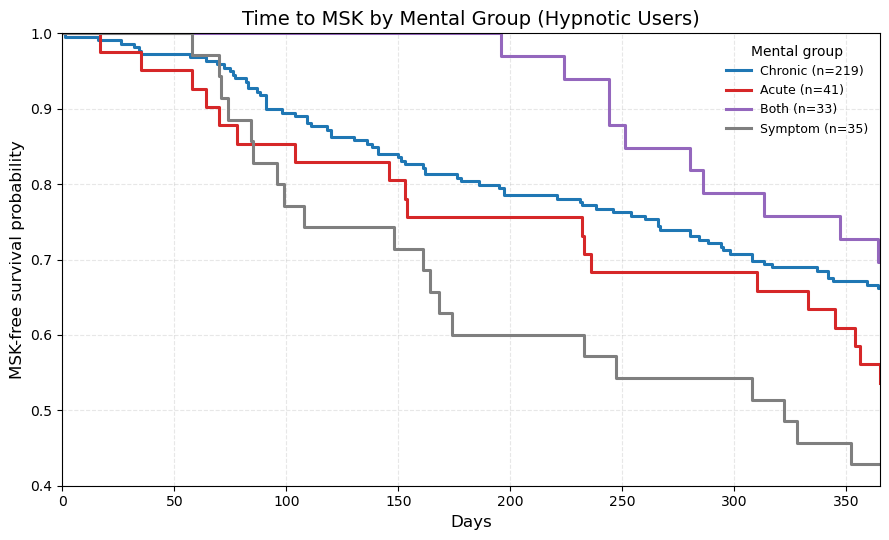

In [339]:

kmf = KaplanMeierFitter()

colors = {
    "chronic": "#1f77b4",  
    "acute": "#d62728",     
    "both": "#9467bd",     
    "symptom": "#7f7f7f"   
}

label_map = {
    "chronic": "Chronic",
    "acute": "Acute",
    "both": "Both",
    "symptom": "Symptom"
}

plt.figure(figsize=(9, 5.5))

for grp in ["chronic", "acute", "both", "symptom"]:
    sub_grp = df[df["Overall_Mental_group"] == grp]

    # hypnotic users
    sub_yes = sub_grp[sub_grp["mental_hypnotic"] == 1]

    if len(sub_yes) < 30:
        print(f"{grp}: skipped (too small)")
        continue

    kmf.fit(
        sub_yes["time_1yr"],
        sub_yes["event_1yr"],
        label=f"{label_map[grp]} (n={len(sub_yes)})"
    )

    kmf.plot_survival_function(
        ci_show=False,
        color=colors[grp],
        linestyle="-",
        linewidth=2.2
    )

plt.title("Time to MSK by Mental Group (Hypnotic Users)", fontsize=14)
plt.xlabel("Days", fontsize=12)

plt.ylabel("MSK-free survival probability", fontsize=12)

plt.xlim(0, 365)
plt.ylim(0.4, 1.0)

plt.grid(alpha=0.3, linestyle="--")

plt.legend(
    title="Mental group",
    fontsize=9,
    title_fontsize=10,
    frameon=False
)

plt.tight_layout()
plt.show()

In [340]:


df_hyp = df[df["mental_hypnotic"] == 1].copy()

valid_groups = []
for grp in ["chronic", "acute", "both", "symptom"]:
    if len(df_hyp[df_hyp["Overall_Mental_group"] == grp]) >= 30:
        valid_groups.append(grp)

df_hyp = df_hyp[df_hyp["Overall_Mental_group"].isin(valid_groups)]

result = multivariate_logrank_test(
    df_hyp["time_1yr"],
    df_hyp["Overall_Mental_group"],
    df_hyp["event_1yr"]
)

print("\n=== Log-rank test (Hypnotic users) ===")
print(f"Chi-square = {result.test_statistic:.3f}")
print(f"p-value   = {result.p_value:.4e}")


=== Log-rank test (Hypnotic users) ===
Chi-square = 10.996
p-value   = 1.1749e-02


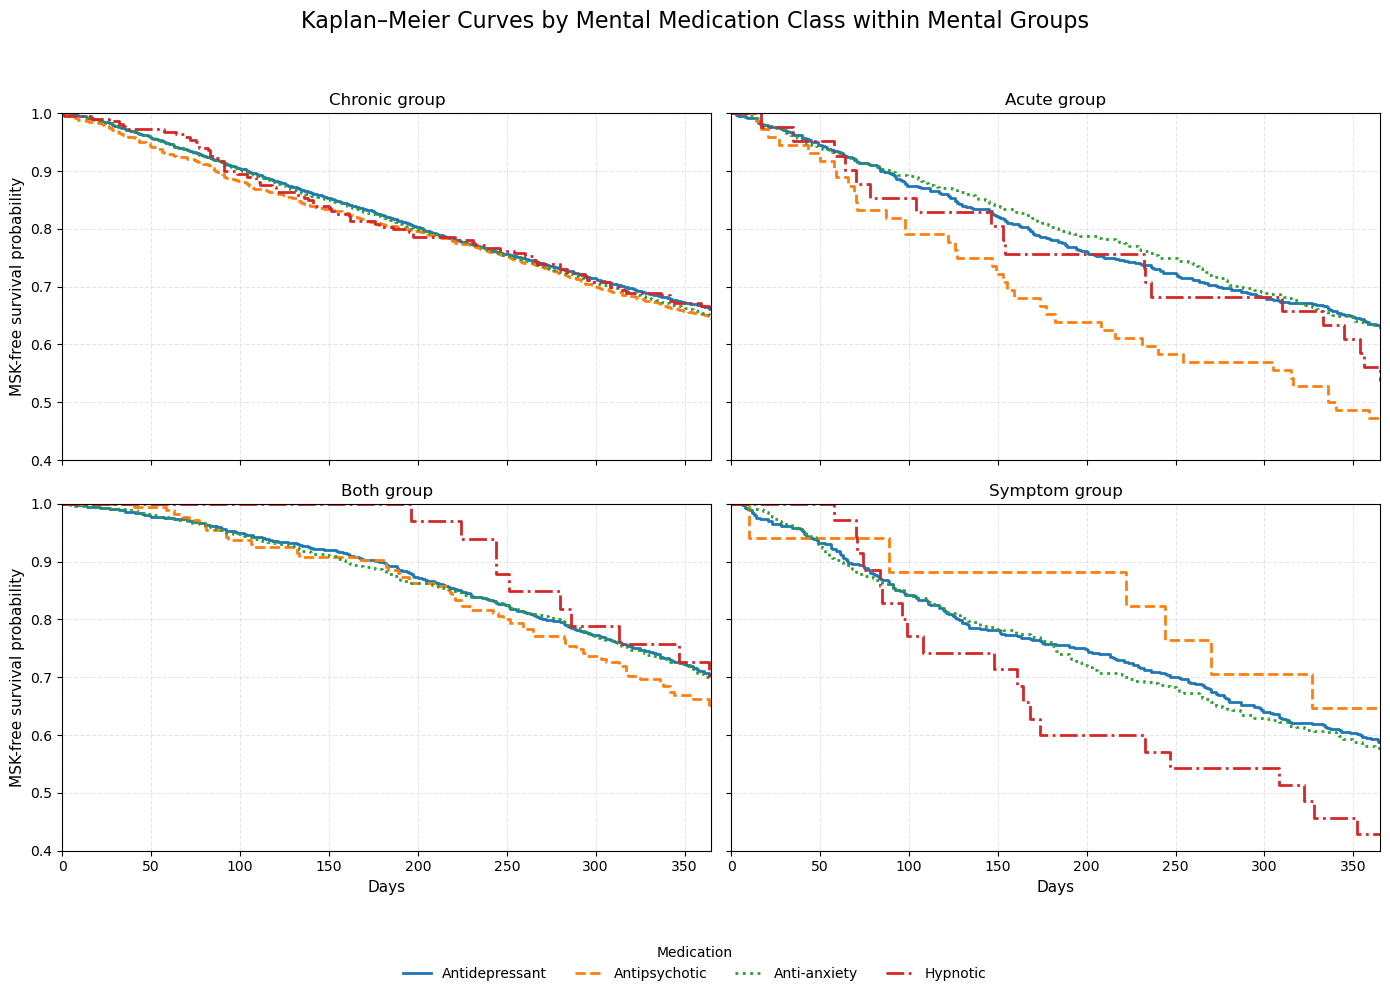

In [341]:


kmf = KaplanMeierFitter()

groups = ["chronic", "acute", "both", "symptom"]
med_vars = [
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic"
]

med_labels = {
    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic"
}

linestyles = {
    "mental_antidepressant": "-",
    "mental_antipsychotic": "--",
    "mental_anti_anxiety": ":",
    "mental_hypnotic": "-."
}

# 可选：统一颜色
colors = {
    "mental_antidepressant": "#1f77b4",
    "mental_antipsychotic": "#ff7f0e",
    "mental_anti_anxiety": "#2ca02c",
    "mental_hypnotic": "#d62728"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

for idx, (ax, grp) in enumerate(zip(axes, groups)):
    sub_grp = df[df["Overall_Mental_group"] == grp].copy()

    for med in med_vars:
        sub = sub_grp[sub_grp[med] == 1].copy()

        kmf.fit(
            durations=sub["time_1yr"],
            event_observed=sub["event_1yr"],
            label=med_labels[med] if idx == 0 else None  
        )

        kmf.plot_survival_function(
            ax=ax,
            ci_show=False,
            linestyle=linestyles[med],
            color=colors[med],
            linewidth=2
        )

    ax.set_title(f"{grp.capitalize()} group", fontsize=12)
    ax.set_xlabel("Days", fontsize=11)
    ax.set_ylabel("MSK-free survival probability", fontsize=11)
    ax.set_xlim(0, 365)
    ax.set_ylim(0.4, 1.0)
    ax.grid(alpha=0.3, linestyle="--")

# 从第一个子图抓 legend handles
handles, labels = axes[0].get_legend_handles_labels()

# 删除每个子图自己的 legend
for ax in axes:
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()

# 统一总 legend
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=10,
    title="Medication"
)

fig.suptitle(
    "Kaplan–Meier Curves by Mental Medication Class within Mental Groups",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

In [342]:

print("\n=== Log-rank test within each mental group: medication Yes vs No ===")

results = []

for grp in groups:
    sub_grp = df[df["Overall_Mental_group"] == grp].copy()

    print(f"\n--- {grp.capitalize()} group ---")

    for med in med_vars:
        yes = sub_grp[sub_grp[med] == 1].copy()
        no = sub_grp[sub_grp[med] == 0].copy()

        n_yes = len(yes)
        n_no = len(no)

        if n_yes == 0 or n_no == 0:
            print(f"{med_labels[med]}: skipped (yes={n_yes}, no={n_no})")
            continue

        res = logrank_test(
            yes["time_1yr"],
            no["time_1yr"],
            event_observed_A=yes["event_1yr"],
            event_observed_B=no["event_1yr"]
        )

        sig = "SIGNIFICANT" if res.p_value < 0.05 else "not significant"

        print(
            f"{med_labels[med]}: "
            f"yes={n_yes}, no={n_no}, "
            f"chi2={res.test_statistic:.3f}, "
            f"p={res.p_value:.4e} -> {sig}"
        )

        results.append({
            "group": grp,
            "medication": med_labels[med],
            "n_yes": n_yes,
            "n_no": n_no,
            "chi2": res.test_statistic,
            "p_value": res.p_value,
            "significant": res.p_value < 0.05
        })

logrank_df = pd.DataFrame(results)


=== Log-rank test within each mental group: medication Yes vs No ===

--- Chronic group ---
Antidepressant: yes=13063, no=16593, chi2=37.093, p=1.1260e-09 -> SIGNIFICANT
Antipsychotic: yes=1256, no=28400, chi2=0.004, p=9.5239e-01 -> not significant
Anti-anxiety: yes=6349, no=23307, chi2=2.309, p=1.2866e-01 -> not significant
Hypnotic: yes=219, no=29437, chi2=0.339, p=5.6013e-01 -> not significant

--- Acute group ---
Antidepressant: yes=733, no=3323, chi2=0.608, p=4.3536e-01 -> not significant
Antipsychotic: yes=72, no=3984, chi2=7.566, p=5.9477e-03 -> SIGNIFICANT
Anti-anxiety: yes=613, no=3443, chi2=0.801, p=3.7087e-01 -> not significant
Hypnotic: yes=41, no=4015, chi2=0.819, p=3.6543e-01 -> not significant

--- Both group ---
Antidepressant: yes=1514, no=952, chi2=1.819, p=1.7741e-01 -> not significant
Antipsychotic: yes=175, no=2291, chi2=1.481, p=2.2362e-01 -> not significant
Anti-anxiety: yes=814, no=1652, chi2=0.091, p=7.6313e-01 -> not significant
Hypnotic: yes=33, no=2433, chi

In [343]:
logrank_df[logrank_df["significant"]].sort_values(["group", "p_value"])

,group,medication,n_yes,n_no,chi2,p_value,significant
5,acute,Antipsychotic,72,3984,7.566072,5.947726e-03,True
0,chronic,Antidepressant,13063,16593,37.093477,1.125998e-09,True
15,symptom,Hypnotic,35,2218,3.940945,4.712430e-02,True


In [344]:
logrank_df.sort_values(["group", "p_value"])

,group,medication,n_yes,n_no,chi2,p_value,significant
5,acute,Antipsychotic,72,3984,7.566072,5.947726e-03,True
7,acute,Hypnotic,41,4015,0.819137,3.654325e-01,False
6,acute,Anti-anxiety,613,3443,0.800755,3.708677e-01,False
4,acute,Antidepressant,733,3323,0.608479,4.353612e-01,False
8,both,Antidepressant,1514,952,1.819222,1.774060e-01,False
9,both,Antipsychotic,175,2291,1.481002,2.236178e-01,False
10,both,Anti-anxiety,814,1652,0.090828,7.631275e-01,False
11,both,Hypnotic,33,2433,0.050810,8.216591e-01,False
0,chronic,Antidepressant,13063,16593,37.093477,1.125998e-09,True
2,chronic,Anti-anxiety,6349,23307,2.308602,1.286597e-01,False


## pain med

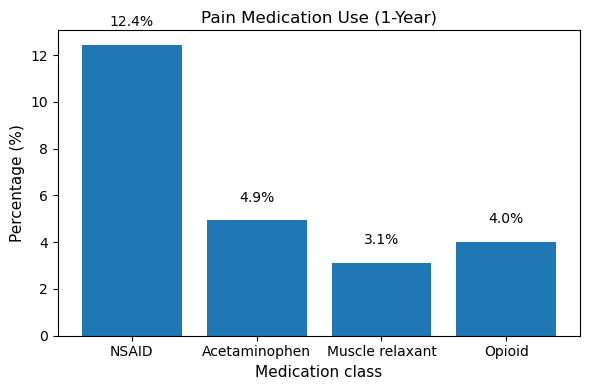

In [345]:

pain_cols = [
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]

# ensure numeric 0/1
for col in pain_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

labels = ["NSAID", "Acetaminophen", "Muscle relaxant", "Opioid"]
plot_vals = [df[c].mean() * 100 for c in pain_cols]

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, plot_vals)

for i, v in enumerate(plot_vals):
    plt.text(i, v + 0.8, f"{v:.1f}%", ha="center")

plt.ylabel("Percentage (%)")
plt.xlabel("Medication class")
plt.title("Pain Medication Use (1-Year)")
plt.tight_layout()
plt.show()

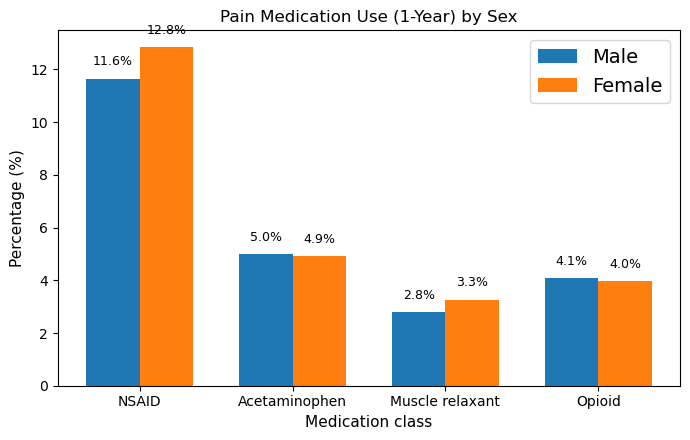

In [346]:
pain_cols = [
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]

# ensure numeric 0/1
for col in pain_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

# 确保 Sex 是字符串
df["Sex"] = df["Sex"].astype(str)

# 计算 Male / Female 各自的 percentage
male_vals = df[df["Sex"] == "M"][pain_cols].mean() * 100
female_vals = df[df["Sex"] == "F"][pain_cols].mean() * 100

labels = ["NSAID", "Acetaminophen", "Muscle relaxant", "Opioid"]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(7, 4.5))

# 两组 bar
bars1 = plt.bar(x - width/2, male_vals, width, label="Male")
bars2 = plt.bar(x + width/2, female_vals, width, label="Female")

# 标注数值
for i, v in enumerate(male_vals):
    plt.text(x[i] - width/2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)

for i, v in enumerate(female_vals):
    plt.text(x[i] + width/2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)

plt.xticks(x, labels)
plt.ylabel("Percentage (%)")
plt.xlabel("Medication class")
plt.title("Pain Medication Use (1-Year) by Sex")
plt.legend()

plt.tight_layout()
plt.show()

/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_88836/1308104580.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["age_group", "Sex"])[pain_cols]


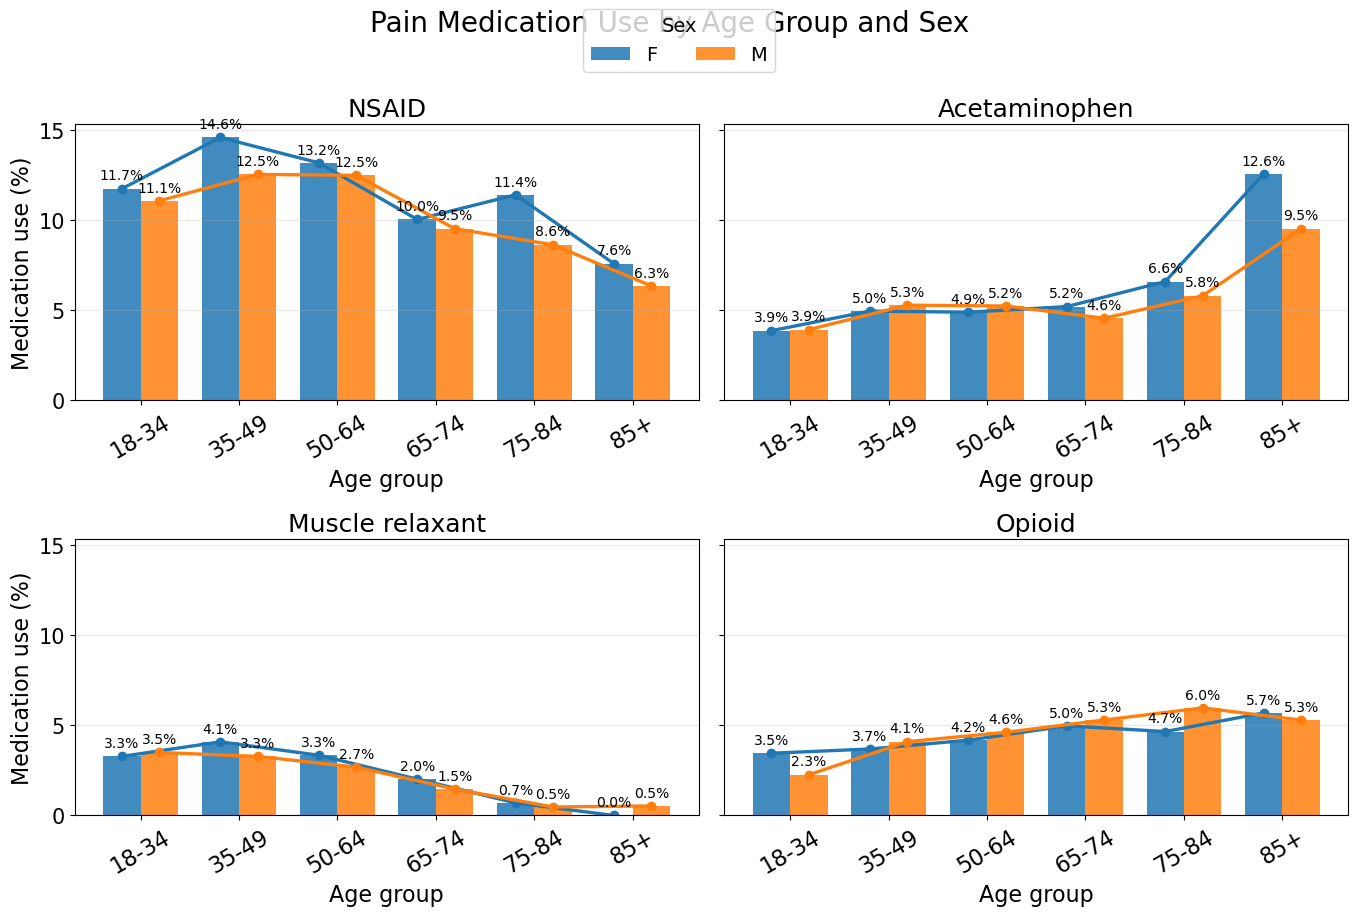

In [347]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 15,
    "legend.fontsize": 14
})

# df = pd.read_csv(...)  # 用你现在的 df
df = df.copy()

pain_cols = [
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]

# clean columns
df.columns = df.columns.str.strip()

for col in pain_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

bins = [18, 35, 50, 65, 75, 85, 200]
age_labels = ["18-34", "35-49", "50-64", "65-74", "75-84", "85+"]

df["age_group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=age_labels,
    right=False
)

sex_colors = {
    "F": "#1f77b4",
    "M": "#ff7f0e"
}

drug_labels = {
    "pain_nsaid": "NSAID",
    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_opioid": "Opioid"
}

summary = (
    df.groupby(["age_group", "Sex"])[pain_cols]
    .mean()
    .mul(100)
    .reset_index()
)

summary["age_group"] = pd.Categorical(
    summary["age_group"],
    categories=age_labels,
    ordered=True
)

summary = summary.sort_values(["age_group", "Sex"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
axes = axes.flatten()

x = np.arange(len(age_labels))
width = 0.38
sex_order = ["F", "M"]

offset_map = {
    "F": -width / 2,
    "M": width / 2
}

for ax, pain_col in zip(axes, pain_cols):
    pivot = summary.pivot(
        index="age_group",
        columns="Sex",
        values=pain_col
    ).reindex(age_labels)

    for sex in sex_order:
        if sex not in pivot.columns:
            continue

        vals = pivot[sex].fillna(0).values

        ax.bar(
            x + offset_map[sex],
            vals,
            width=width,
            label=sex,
            alpha=0.85,
            color=sex_colors[sex]
        )

        ax.plot(
            x + offset_map[sex],
            vals,
            marker="o",
            linewidth=2.4,
            color=sex_colors[sex]
        )

        for i, v in enumerate(vals):
            ax.text(
                x[i] + offset_map[sex],
                v + 0.35,
                f"{v:.1f}%",
                ha="center",
                va="bottom",
                fontsize=10
            )

    ax.set_title(drug_labels[pain_col])
    ax.set_xticks(x)
    ax.set_xticklabels(age_labels, rotation=30)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Medication use (%)")
axes[2].set_ylabel("Medication use (%)")

for ax in axes:
    ax.set_xlabel("Age group")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Sex", loc="upper center", ncol=2)

fig.suptitle("Pain Medication Use by Age Group and Sex", fontsize=20, y=1.02)

plt.tight_layout()
plt.show()

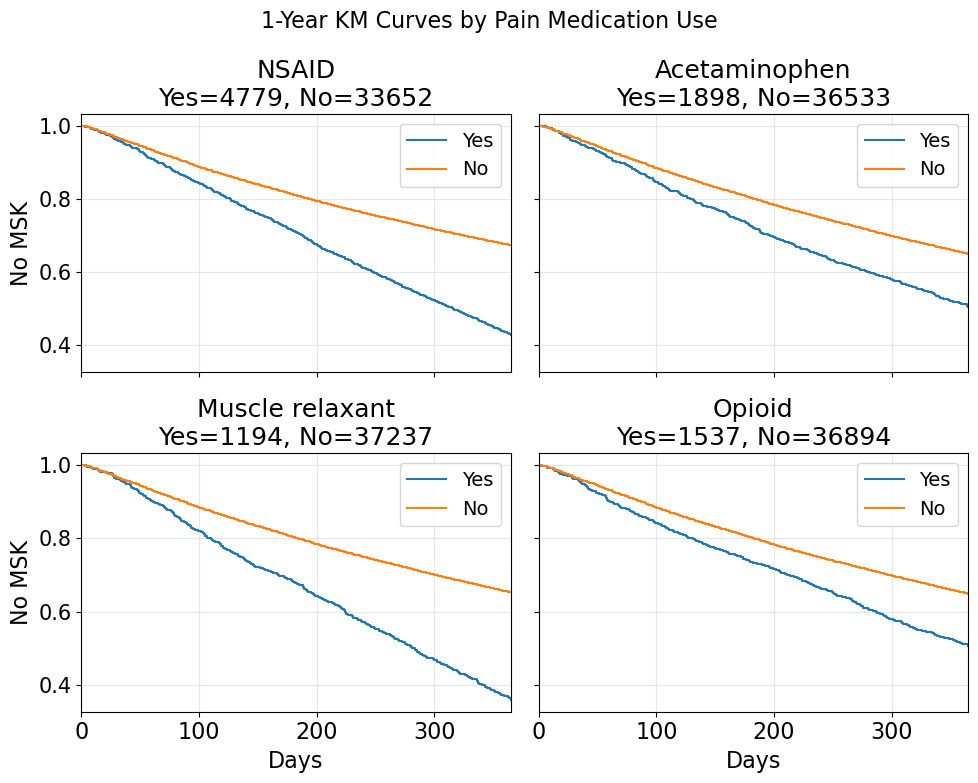

In [348]:

df = df.copy()
df["time_to_msk_days"] = pd.to_numeric(df["time_to_msk_days"], errors="coerce")

df["event_1yr"] = (
    df["time_to_msk_days"].notna() &
    (df["time_to_msk_days"] <= 365)
).astype(int)

df["time_1yr"] = np.where(
    df["event_1yr"] == 1,
    df["time_to_msk_days"],
    365
)

pain_cols = [
    "pain_nsaid",
    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_opioid",
]

for col in pain_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

title_map = {
    "pain_nsaid": "NSAID",
    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_opioid": "Opioid",
}


fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, col in zip(axes, pain_cols):
    kmf = KaplanMeierFitter()

    for val, label in [(1, "Yes"), (0, "No")]:
        sub = df[df[col] == val].copy()
        if sub.empty:
            continue

        kmf.fit(
            durations=sub["time_1yr"],
            event_observed=sub["event_1yr"],
            label=label
        )
        kmf.plot_survival_function(ax=ax, ci_show=False)

    n_yes = int((df[col] == 1).sum())
    n_no = int((df[col] == 0).sum())

    ax.set_title(f"{title_map[col]}\nYes={n_yes}, No={n_no}")
    ax.set_xlabel("Days")
    ax.set_ylabel("No MSK")
    ax.set_xlim(0, 365)
    ax.grid(alpha=0.3)

fig.suptitle("1-Year KM Curves by Pain Medication Use", fontsize=16)
plt.tight_layout()
plt.show()

In [349]:


for col in pain_cols:
    yes = df[df[col] == 1].copy()
    no = df[df[col] == 0].copy()

    result = logrank_test(
        yes["time_1yr"], no["time_1yr"],
        event_observed_A=yes["event_1yr"],
        event_observed_B=no["event_1yr"]
    )

    print(f"{title_map[col]}: p = {result.p_value:.4g}")

NSAID: p = 4.237e-244
Acetaminophen: p = 3.703e-39
Muscle relaxant: p = 6.887e-105
Opioid: p = 1.032e-30


## Test train set

In [350]:


df_model = pd.read_csv(OUTDIR / "df_1yr_from_long.csv").copy()

# outcome + age
df_model["MSK_Diagnosis_1yr"] = pd.to_numeric(
    df_model["MSK_Diagnosis_1yr"], errors="coerce"
).fillna(0).astype(int)
df_model["Age"] = pd.to_numeric(df_model["Age"], errors="coerce")

# Sex: M = baseline
df_model["Sex"] = (
    df_model["Sex"].astype("category").cat.reorder_categories(["M", "F"])
)

# Overall_Mental_group: chronic = baseline
df_model["Overall_Mental_group"] = (
    df_model["Overall_Mental_group"]
    .astype("category")
    .cat.reorder_categories(["chronic", "acute", "both", "symptom"])
)

# mental group dummies (chronic = baseline) — same encoding as correlation matrix
df_model["mental_acute"]   = (df_model["Overall_Mental_group"] == "acute").astype(int)
df_model["mental_both"]    = (df_model["Overall_Mental_group"] == "both").astype(int)
df_model["mental_symptom"] = (df_model["Overall_Mental_group"] == "symptom").astype(int)

# numeric counts (from correlation matrix)
for c in ["Pre_existing_condition_count", "Multimorbidity_count", "Mental_Diagnosis_count"]:
    df_model[c] = pd.to_numeric(df_model[c], errors="coerce")

# medication columns (0/1) — matches the correlation matrix (no pain_acetaminophen)
mental_meds = [
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",
]
pain_meds = [
    "pain_nsaid",
    "pain_muscle_relaxant",
    "pain_opioid",
]
med_cols = mental_meds + pain_meds

for c in med_cols:
    df_model[c] = pd.to_numeric(df_model[c], errors="coerce").fillna(0).astype(int)

need = [
    "Age", "Sex", "Overall_Mental_group", "MSK_Diagnosis_1yr",
    "Pre_existing_condition_count", "Multimorbidity_count", "Mental_Diagnosis_count",
]
df_model = df_model.dropna(subset=need).copy()

print("Modeling df shape:", df_model.shape)
print("MSK 1yr rate:", df_model["MSK_Diagnosis_1yr"].mean().round(3))


Modeling df shape: (38431, 56)
MSK 1yr rate: 0.357


In [351]:

train_df, test_df = train_test_split(
    df_model,
    test_size=0.30,
    random_state=42,
    stratify=df_model["MSK_Diagnosis_1yr"],
)

print(f"Train : {train_df.shape}  | MSK rate: {train_df['MSK_Diagnosis_1yr'].mean():.3f}")
print(f"Test  : {test_df.shape}  | MSK rate: {test_df['MSK_Diagnosis_1yr'].mean():.3f}")


Train : (26901, 56)  | MSK rate: 0.357
Test  : (11530, 56)  | MSK rate: 0.357


In [352]:
model_0 = smf.logit(
    "MSK_Diagnosis_1yr ~ Age + C(Sex)",
    data=train_df
).fit()
print(model_0.summary())

Optimization terminated successfully.
         Current function value: 0.646620
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26898
Method:                           MLE   Df Model:                            2
Date:                Fri, 01 May 2026   Pseudo R-squ.:                0.007731
Time:                        16:10:31   Log-Likelihood:                -17395.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                 1.382e-59
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -1.2428      0.045    -27.829      0.000      -1.330      -1.155
C(Sex)[T.F]     0.0505    

In [353]:
model_1 = smf.logit(
    "MSK_Diagnosis_1yr ~ Age + C(Sex) + Age:C(Sex) ",
    data=train_df
).fit()
print(model_1.summary())

Optimization terminated successfully.
         Current function value: 0.646527
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26897
Method:                           MLE   Df Model:                            3
Date:                Fri, 01 May 2026   Pseudo R-squ.:                0.007874
Time:                        16:10:36   Log-Likelihood:                -17392.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                 1.511e-59
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -1.1186      0.071    -15.745      0.000      -1.258      -0.979
C(Sex)[T.F]   

In [354]:
model_2 = smf.logit(
    "MSK_Diagnosis_1yr ~ Age + C(Sex) + Age:C(Sex) + Pre_existing_condition_count",
    data=train_df
).fit()
print(model_2.summary())

Optimization terminated successfully.
         Current function value: 0.646185
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26896
Method:                           MLE   Df Model:                            4
Date:                Fri, 01 May 2026   Pseudo R-squ.:                0.008400
Time:                        16:10:39   Log-Likelihood:                -17383.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                 1.669e-62
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -1.1055      0.071    -15.551      0.000

In [355]:
model_3 = smf.logit(
    "MSK_Diagnosis_1yr ~ Age + C(Sex) + Age:C(Sex)+  Mental_Diagnosis_count+ Pre_existing_condition_count + Multimorbidity_count",
    data=train_df
).fit()
print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.638536
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26894
Method:                           MLE   Df Model:                            6
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.02014
Time:                        16:10:42   Log-Likelihood:                -17177.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                3.132e-149
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -1.0155      0.078    -12.954      0.000

In [356]:
model_4 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) +  Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group)",
    data=train_df
).fit()

print(model_4.summary())

Optimization terminated successfully.
         Current function value: 0.638340
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26891
Method:                           MLE   Df Model:                            9
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.02044
Time:                        16:10:46   Log-Likelihood:                -17172.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                1.899e-148
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                             -1.0468      0.081    

In [357]:
summary_df4 = model_4.summary2().tables[1]

or_df4 = summary_df4.copy()
or_df4["OR"] = np.exp(or_df4["Coef."])
or_df4["CI_low"] = np.exp(or_df4["Coef."] - 1.96 * or_df4["Std.Err."])
or_df4["CI_high"] = np.exp(or_df4["Coef."] + 1.96 * or_df4["Std.Err."])

print(or_df4.round(3))

                                    Coef.  Std.Err.       z  P>|z|  [0.025  \
Intercept                          -1.047     0.081 -12.964  0.000  -1.205   
C(Sex)[T.F]                        -0.066     0.088  -0.752  0.452  -0.238   
C(Overall_Mental_group)[T.acute]    0.068     0.042   1.614  0.106  -0.015   
C(Overall_Mental_group)[T.both]    -0.004     0.064  -0.056  0.956  -0.130   
C(Overall_Mental_group)[T.symptom]  0.162     0.054   2.991  0.003   0.056   
Age                                 0.013     0.001   9.166  0.000   0.010   
Age:C(Sex)[T.F]                     0.003     0.002   1.710  0.087  -0.000   
Mental_Diagnosis_count             -0.096     0.029  -3.258  0.001  -0.153   
Pre_existing_condition_count        0.142     0.014  10.282  0.000   0.115   
Multimorbidity_count               -0.299     0.016 -18.891  0.000  -0.330   

                                    0.975]     OR  CI_low  CI_high  
Intercept                           -0.889  0.351   0.300    0.411  
C(S

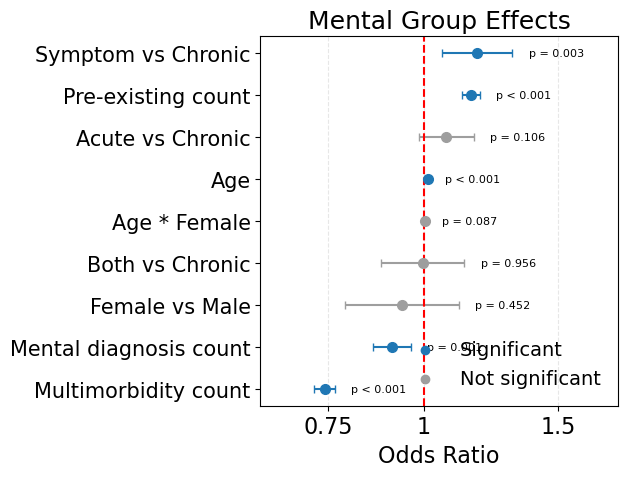

In [358]:
df = model_4.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})
df = df[df["term"] != "Intercept"].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "Age:C(Sex)[T.F]": "Age * Female",
    "C(Overall_Mental_group)[T.acute]": "Acute vs Chronic",
    "C(Overall_Mental_group)[T.both]": "Both vs Chronic",
    "C(Overall_Mental_group)[T.symptom]": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing count",
    "Multimorbidity_count": "Multimorbidity count"
}

plot_df = df[df["term"].isin(label_map.keys())].copy()
plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

plt.figure(figsize=(6.5, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.25
ax.set_xlim(xmin, xmax * 1.10)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=8,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

ax.set_xlabel("Odds Ratio")
ax.set_title("Mental Group Effects")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

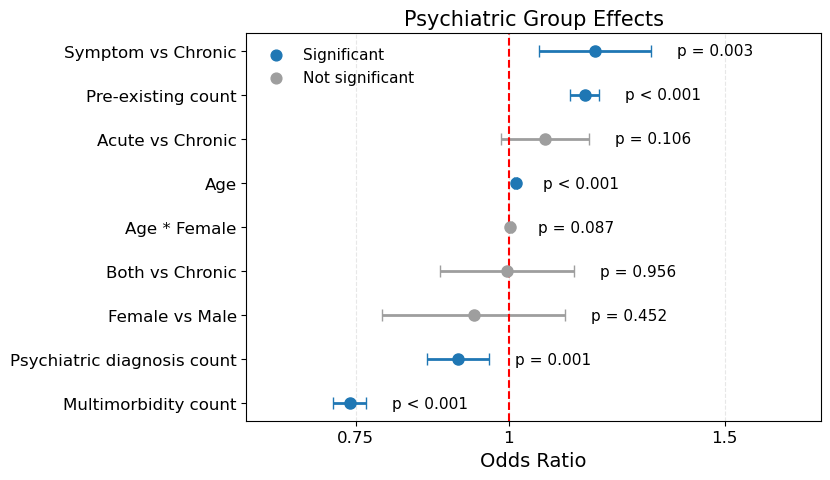

In [359]:

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11
})

df = model_4.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})
df = df[df["term"] != "Intercept"].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "Age:C(Sex)[T.F]": "Age * Female",
    "C(Overall_Mental_group)[T.acute]": "Acute vs Chronic",
    "C(Overall_Mental_group)[T.both]": "Both vs Chronic",
    "C(Overall_Mental_group)[T.symptom]": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Psychiatric diagnosis count",
    "Pre_existing_condition_count": "Pre-existing count",
    "Multimorbidity_count": "Multimorbidity count"
}

plot_df = df[df["term"].isin(label_map.keys())].copy()
plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.25
ax.set_xlim(xmin, xmax * 1.10)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="upper left", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Psychiatric Group Effects", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [360]:
model_5 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) +  Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group)+"
    "Mental_related_medication_class_count+Pain_related_medication_class_count",
    data=train_df
).fit()

print(model_5.summary())

Optimization terminated successfully.
         Current function value: 0.619598
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26889
Method:                           MLE   Df Model:                           11
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.04920
Time:                        16:10:53   Log-Likelihood:                -16668.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
Intercept                                -1.1713      

In [361]:
summary_df5 = model_5.summary2().tables[1]

or_df6 = summary_df5.copy()
or_df6["OR"] = np.exp(or_df6["Coef."])
or_df6["CI_low"] = np.exp(or_df6["Coef."] - 1.96 * or_df6["Std.Err."])
or_df6["CI_high"] = np.exp(or_df6["Coef."] + 1.96 * or_df6["Std.Err."])

print(or_df6.round(3))

                                       Coef.  Std.Err.       z  P>|z|  [0.025  \
Intercept                             -1.171     0.083 -14.182  0.000  -1.333   
C(Sex)[T.F]                           -0.070     0.089  -0.780  0.436  -0.245   
C(Overall_Mental_group)[T.acute]       0.043     0.043   1.003  0.316  -0.041   
C(Overall_Mental_group)[T.both]       -0.042     0.066  -0.639  0.523  -0.172   
C(Overall_Mental_group)[T.symptom]     0.116     0.055   2.104  0.035   0.008   
Age                                    0.014     0.001   9.320  0.000   0.011   
Age:C(Sex)[T.F]                        0.003     0.002   1.813  0.070  -0.000   
Mental_Diagnosis_count                -0.106     0.031  -3.443  0.001  -0.167   
Pre_existing_condition_count           0.148     0.014  10.484  0.000   0.120   
Multimorbidity_count                  -0.319     0.016 -19.680  0.000  -0.351   
Mental_related_medication_class_count -0.108     0.019  -5.671  0.000  -0.145   
Pain_related_medication_clas

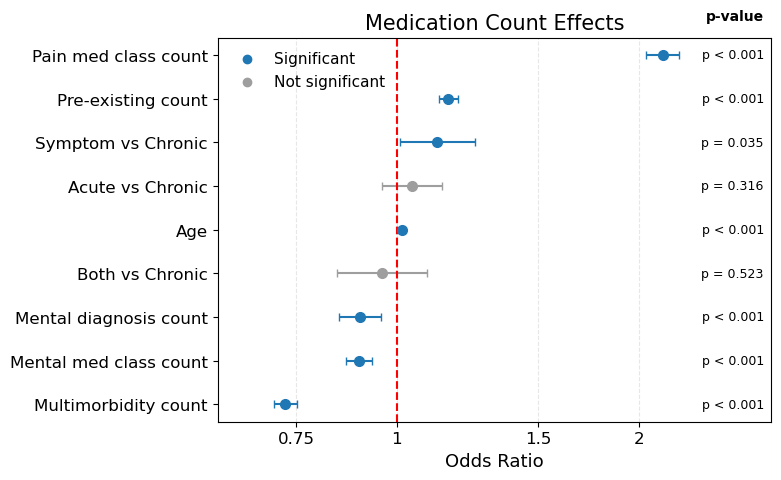

In [362]:

df = model_5.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})


df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "acute",
    "both",
    "symptom",
    "Age",
    "C(Sex)[T.F]",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",
    "Mental_related_medication_class_count",
    "Pain_related_medication_class_count"
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing count",
    "Multimorbidity_count": "Multimorbidity count",
    "Mental_related_medication_class_count": "Mental med class count",
    "Pain_related_medication_class_count": "Pain med class count"
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)
plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.3
ax.set_xlim(xmin, xmax)
ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

# forest plot
for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        xmax * 0.98,
        i,
        p_text,
        ha="right",
        va="center",
        fontsize=9,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])
ax.text(
    xmax * 0.98,
    len(plot_df) - 0.2,
    "p-value",
    ha="right",
    fontsize=10,
    fontweight="bold"
)

# legend
ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

# labels
ax.set_xlabel("Odds Ratio")
ax.set_title("Medication Count Effects")

# grid
ax.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [363]:
model_6 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) +  Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group)+"
    "mental_antidepressant + mental_antipsychotic + "
    "mental_anti_anxiety + mental_hypnotic + "
    "Pain_related_medication_class_count",
    data=train_df
).fit()

print(model_6.summary())

Optimization terminated successfully.
         Current function value: 0.619543
         Iterations 5


                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26886
Method:                           MLE   Df Model:                           14
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.04928
Time:                        16:11:01   Log-Likelihood:                -16666.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              -1.1666      0.083    -14.107      0.000      -1.329      -1.005
C(Sex)[T.F]                            -0.0645      0.08

In [364]:
summary_df6 = model_6.summary2().tables[1]

or_df6 = summary_df6.copy()
or_df6["OR"] = np.exp(or_df6["Coef."])
or_df6["CI_low"] = np.exp(or_df6["Coef."] - 1.96 * or_df6["Std.Err."])
or_df6["CI_high"] = np.exp(or_df6["Coef."] + 1.96 * or_df6["Std.Err."])

print(or_df6.round(3))

                                     Coef.  Std.Err.       z  P>|z|  [0.025  \
Intercept                           -1.167     0.083 -14.107  0.000  -1.329   
C(Sex)[T.F]                         -0.065     0.089  -0.721  0.471  -0.240   
C(Overall_Mental_group)[T.acute]     0.040     0.043   0.916  0.360  -0.045   
C(Overall_Mental_group)[T.both]     -0.041     0.066  -0.615  0.539  -0.171   
C(Overall_Mental_group)[T.symptom]   0.114     0.055   2.061  0.039   0.006   
Age                                  0.014     0.001   9.305  0.000   0.011   
Age:C(Sex)[T.F]                      0.003     0.002   1.789  0.074  -0.000   
Mental_Diagnosis_count              -0.107     0.031  -3.473  0.001  -0.168   
Pre_existing_condition_count         0.148     0.014  10.501  0.000   0.121   
Multimorbidity_count                -0.319     0.016 -19.667  0.000  -0.351   
mental_antidepressant               -0.128     0.029  -4.485  0.000  -0.185   
mental_antipsychotic                -0.000     0.069

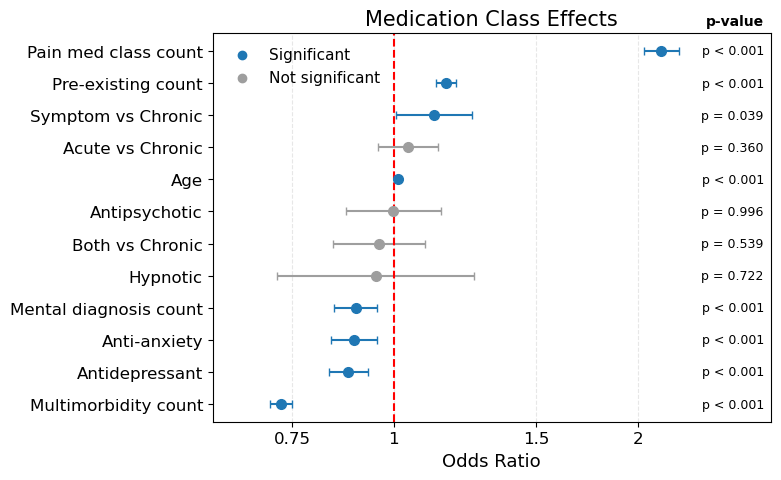

In [365]:

summary_df = model_6.summary2().tables[1].copy()

or_df = summary_df.copy()
or_df["OR"] = np.exp(or_df["Coef."])
or_df["CI_low"] = np.exp(or_df["Coef."] - 1.96 * or_df["Std.Err."])
or_df["CI_high"] = np.exp(or_df["Coef."] + 1.96 * or_df["Std.Err."])
or_df["sig"] = or_df["P>|z|"] < 0.05

or_df = or_df.reset_index().rename(columns={"index": "term"})

or_df["term"] = or_df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
or_df["term"] = or_df["term"].str.replace(r"\]", "", regex=True)

plot_df = or_df[or_df["term"] != "Intercept"].copy()


keep_terms = [
    "Age",
    "C(Sex)[T.F]",
    "acute",
    "both",
    "symptom",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",
    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",
    "Pain_related_medication_class_count"
]

plot_df = plot_df[plot_df["term"].isin(keep_terms)].copy()


label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing count",
    "Multimorbidity_count": "Multimorbidity count",
    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",
    "Pain_related_medication_class_count": "Pain med class count"
}

plot_df["label"] = plot_df["term"].map(label_map)


plot_df = plot_df.sort_values("OR").reset_index(drop=True)

plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.3
ax.set_xlim(xmin, xmax)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        xmax * 0.98,
        i,
        p_text,
        ha="right",
        va="center",
        fontsize=9
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

# y axis
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])
ax.text(
    xmax * 0.98,
    len(plot_df) - 0.2,
    "p-value",
    ha="right",
    fontsize=10,
    fontweight="bold"
)

# legend
ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

# labels
ax.set_xlabel("Odds Ratio")
ax.set_title("Medication Class Effects")

# grid
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [366]:
model_7 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) + Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group) * mental_antidepressant + "
    "mental_antipsychotic + "
    "mental_anti_anxiety + mental_hypnotic + "
    "Pain_related_medication_class_count",
    data=train_df
).fit()
print(model_7.summary())

Optimization terminated successfully.
         Current function value: 0.619537
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26883
Method:                           MLE   Df Model:                           17
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.04929
Time:                        16:11:10   Log-Likelihood:                -16666.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept       

In [367]:
summary_df7 = model_7.summary2().tables[1]

or_df7 = summary_df7.copy()
or_df7["OR"] = np.exp(or_df7["Coef."])
or_df7["CI_low"] = np.exp(or_df7["Coef."] - 1.96 * or_df7["Std.Err."])
or_df7["CI_high"] = np.exp(or_df7["Coef."] + 1.96 * or_df7["Std.Err."])

print(or_df7.round(3))

                                                          Coef.  Std.Err.  \
Intercept                                                -1.165     0.083   
C(Sex)[T.F]                                              -0.064     0.090   
C(Overall_Mental_group)[T.acute]                          0.035     0.049   
C(Overall_Mental_group)[T.both]                          -0.058     0.094   
C(Overall_Mental_group)[T.symptom]                        0.100     0.062   
Age                                                       0.014     0.001   
Age:C(Sex)[T.F]                                           0.003     0.002   
Mental_Diagnosis_count                                   -0.107     0.031   
Pre_existing_condition_count                              0.148     0.014   
Multimorbidity_count                                     -0.319     0.016   
mental_antidepressant                                    -0.135     0.031   
C(Overall_Mental_group)[T.acute]:mental_antidepressant    0.021     0.108   

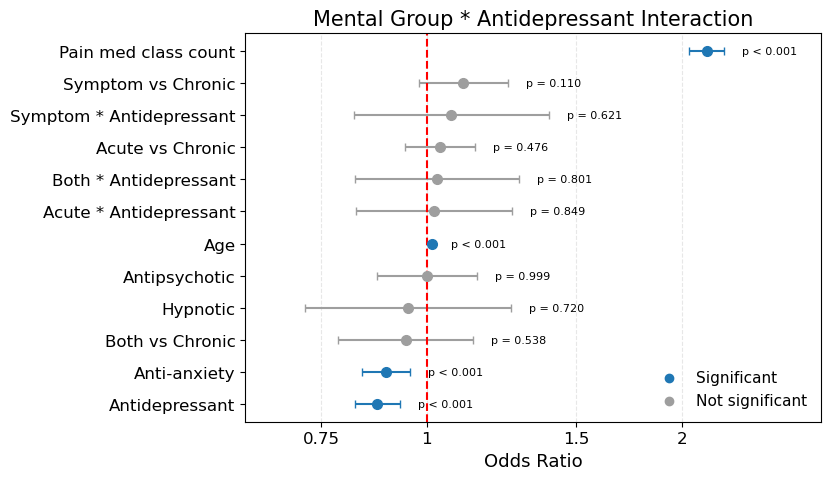

In [368]:
df = model_7.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)
df["term"] = df["term"].str.replace(":", " × ", regex=False)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F]",
    "acute",
    "both",
    "symptom",
    "mental_antidepressant",
    "acute × mental_antidepressant",
    "both × mental_antidepressant",
    "symptom × mental_antidepressant",
    "mental_anti_anxiety",
    "mental_antipsychotic",
    "mental_hypnotic",
    "Pain_related_medication_class_count",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "mental_antidepressant": "Antidepressant",
    "acute × mental_antidepressant": "Acute * Antidepressant",
    "both × mental_antidepressant": "Both * Antidepressant",
    "symptom × mental_antidepressant": "Symptom * Antidepressant",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_antipsychotic": "Antipsychotic",
    "mental_hypnotic": "Hypnotic",
    "Pain_related_medication_class_count": "Pain med class count",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

plt.figure(figsize=(8.5, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.3
ax.set_xlim(xmin, xmax)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    # 👉 放点右边
    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=8
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

# legend
ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

ax.set_xlabel("Odds Ratio")
ax.set_title("Mental Group * Antidepressant Interaction")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

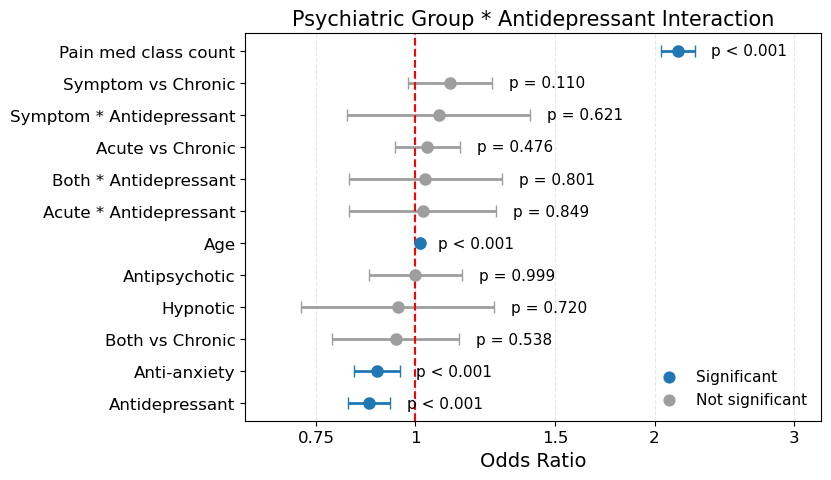

In [369]:

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11
})

df = model_7.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)
df["term"] = df["term"].str.replace(":", " × ", regex=False)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F]",
    "acute",
    "both",
    "symptom",
    "mental_antidepressant",
    "acute × mental_antidepressant",
    "both × mental_antidepressant",
    "symptom × mental_antidepressant",
    "mental_anti_anxiety",
    "mental_antipsychotic",
    "mental_hypnotic",
    "Pain_related_medication_class_count",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "mental_antidepressant": "Antidepressant",
    "acute × mental_antidepressant": "Acute * Antidepressant",
    "both × mental_antidepressant": "Both * Antidepressant",
    "symptom × mental_antidepressant": "Symptom * Antidepressant",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_antipsychotic": "Antipsychotic",
    "mental_hypnotic": "Hypnotic",
    "Pain_related_medication_class_count": "Pain med class count",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.30
ax.set_xlim(xmin, xmax * 1.11)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

# legend
ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="lower right", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Psychiatric Group * Antidepressant Interaction", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [370]:
from scipy import stats
import numpy as np
import pandas as pd

params = model_7.params
cov = model_7.cov_params()

groups = ["chronic", "acute", "both", "symptom"]
rows = []

for g in groups:
    coef_names = ["mental_antidepressant"]

    if g != "chronic":
        candidates = [
            f'C(Overall_Mental_group, Treatment(reference="chronic"))[T.{g}]:mental_antidepressant',
            f'mental_antidepressant:C(Overall_Mental_group, Treatment(reference="chronic"))[T.{g}]',
            f'C(Overall_Mental_group)[T.{g}]:mental_antidepressant',
            f'mental_antidepressant:C(Overall_Mental_group)[T.{g}]',
        ]

        inter_name = next((x for x in candidates if x in params.index), None)

        if inter_name is None:
            print(f"Missing interaction for {g}")
        else:
            coef_names.append(inter_name)

    beta = sum(params[name] for name in coef_names)

    var = 0
    for a in coef_names:
        for b in coef_names:
            var += cov.loc[a, b]

    se = np.sqrt(var)

    OR = np.exp(beta)
    CI_low = np.exp(beta - 1.96 * se)
    CI_high = np.exp(beta + 1.96 * se)
    z = beta / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))

    rows.append({
        "Mental_group": g,
        "OR_Antidepressant": OR,
        "CI_low": CI_low,
        "CI_high": CI_high,
        "p_value": p,
        "terms_used": " + ".join(coef_names)
    })

antidepressant_or_by_group = pd.DataFrame(rows)
antidepressant_or_by_group

,Mental_group,OR_Antidepressant,CI_low,CI_high,p_value,terms_used
0,chronic,0.873912,0.821631,0.929520,0.000019,mental_antidepressant
1,acute,0.892099,0.727628,1.093747,0.272139,mental_antidepressant + C(Overall_Mental_group)[T.acute]:mental_antidepressant
2,both,0.899353,0.725071,1.115526,0.334429,mental_antidepressant + C(Overall_Mental_group)[T.both]:mental_antidepressant
3,symptom,0.934248,0.721925,1.209018,0.605123,mental_antidepressant + C(Overall_Mental_group)[T.symptom]:mental_antidepressant


In [371]:
model_8 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) + Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group) * mental_anti_anxiety + "
    "mental_antipsychotic + "
    "mental_anti_anxiety + mental_hypnotic + "
    "Pain_related_medication_class_count",
    data=train_df
).fit()
print(model_8.summary())

Optimization terminated successfully.
         Current function value: 0.619887
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26884
Method:                           MLE   Df Model:                           16
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.04875
Time:                        16:11:14   Log-Likelihood:                -16676.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                             coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------
Intercept           

In [372]:
summary_df8 = model_8.summary2().tables[1]

or_df8 = summary_df8.copy()
or_df8["OR"] = np.exp(or_df8["Coef."])
or_df8["CI_low"] = np.exp(or_df8["Coef."] - 1.96 * or_df8["Std.Err."])
or_df8["CI_high"] = np.exp(or_df8["Coef."] + 1.96 * or_df8["Std.Err."])

print(or_df8.round(3))

                                                        Coef.  Std.Err.  \
Intercept                                              -1.186     0.083   
C(Sex)[T.F]                                            -0.078     0.089   
C(Overall_Mental_group)[T.acute]                        0.078     0.047   
C(Overall_Mental_group)[T.both]                        -0.018     0.076   
C(Overall_Mental_group)[T.symptom]                      0.110     0.061   
Age                                                     0.014     0.001   
Age:C(Sex)[T.F]                                         0.003     0.002   
Mental_Diagnosis_count                                 -0.131     0.030   
Pre_existing_condition_count                            0.151     0.014   
Multimorbidity_count                                   -0.321     0.016   
mental_anti_anxiety                                    -0.127     0.038   
C(Overall_Mental_group)[T.acute]:mental_anti_anxiety   -0.069     0.118   
C(Overall_Mental_group)[T

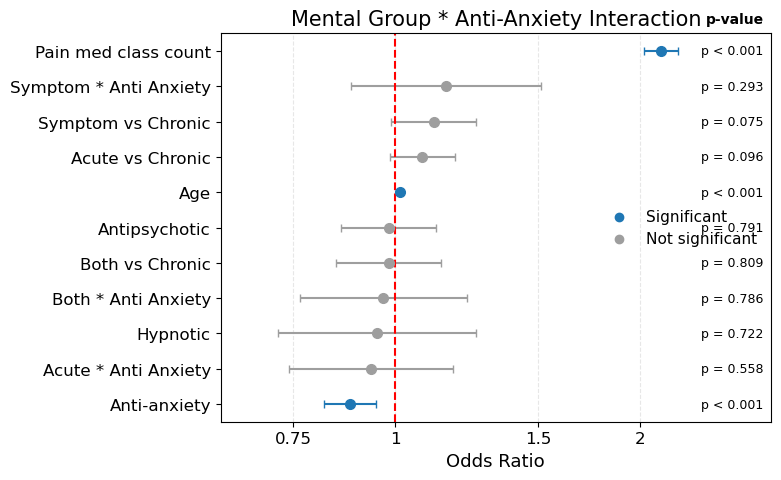

In [373]:

df = model_8.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})


df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)
df["term"] = df["term"].str.replace(":", " × ", regex=False)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F]",
    "acute",
    "both",
    "symptom",
    "mental_antidepressant",
    "acute × mental_anti_anxiety",
    "both × mental_anti_anxiety",
    "symptom × mental_anti_anxiety",
    "mental_anti_anxiety",
    "mental_antipsychotic",
    "mental_hypnotic",
    "Pain_related_medication_class_count",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "mental_antidepressant": "Antidepressant",
    "acute × mental_anti_anxiety": "Acute * Anti Anxiety",
    "both × mental_anti_anxiety": "Both * Anti Anxiety",
    "symptom × mental_anti_anxiety": "Symptom * Anti Anxiety",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_antipsychotic": "Antipsychotic",
    "mental_hypnotic": "Hypnotic",
    "Pain_related_medication_class_count": "Pain med class count",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)


plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.3
ax.set_xlim(xmin, xmax)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

# forest plot
for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        xmax * 0.98,
        i,
        p_text,
        ha="right",
        va="center",
        fontsize=9
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.text(
    xmax * 0.98,
    len(plot_df) - 0.2,
    "p-value",
    ha="right",
    fontsize=10,
    fontweight="bold"
)

# legend
ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

# labels
ax.set_xlabel("Odds Ratio")
ax.set_title("Mental Group * Anti-Anxiety Interaction")

# grid
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Optimization terminated successfully.
         Current function value: 0.619782
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26884
Method:                           MLE   Df Model:                           16
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.04892
Time:                        16:11:19   Log-Likelihood:                -16673.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                   

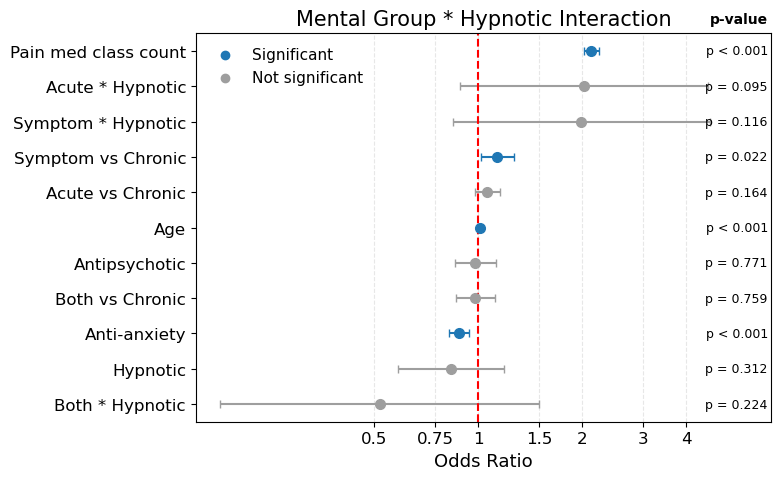

In [374]:
model_9 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) + Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group) * mental_hypnotic + "
    "mental_antipsychotic + "
    "mental_anti_anxiety + mental_hypnotic + "
    "Pain_related_medication_class_count",
    data=train_df
).fit()
print(model_9.summary())


summary_df9 = model_9.summary2().tables[1]

or_df9 = summary_df9.copy()
or_df9["OR"] = np.exp(or_df9["Coef."])
or_df9["CI_low"] = np.exp(or_df9["Coef."] - 1.96 * or_df9["Std.Err."])
or_df9["CI_high"] = np.exp(or_df9["Coef."] + 1.96 * or_df9["Std.Err."])

print(or_df9.round(3))


df = model_9.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})
df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)
df["term"] = df["term"].str.replace(":", " × ", regex=False)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F]",
    "acute",
    "both",
    "symptom",
    "mental_antidepressant",
    "acute × mental_hypnotic",
    "both × mental_hypnotic",
    "symptom × mental_hypnotic",
    "mental_anti_anxiety",
    "mental_antipsychotic",
    "mental_hypnotic",
    "Pain_related_medication_class_count",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "mental_antidepressant": "Antidepressant",
    "acute × mental_hypnotic": "Acute * Hypnotic",
    "both × mental_hypnotic": "Both * Hypnotic",
    "symptom × mental_hypnotic": "Symptom * Hypnotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_antipsychotic": "Antipsychotic",
    "mental_hypnotic": "Hypnotic",
    "Pain_related_medication_class_count": "Pain med class count",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)


plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.50
ax.set_xlim(xmin, xmax)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

# forest plot
for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        xmax * 0.98,
        i,
        p_text,
        ha="right",
        va="center",
        fontsize=9
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.text(
    xmax * 0.98,
    len(plot_df) - 0.2,
    "p-value",
    ha="right",
    fontsize=10,
    fontweight="bold"
)

# legend
ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

# labels
ax.set_xlabel("Odds Ratio")
ax.set_title("Mental Group * Hypnotic Interaction")

# grid
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Optimization terminated successfully.
         Current function value: 0.619798
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:      MSK_Diagnosis_1yr   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26884
Method:                           MLE   Df Model:                           16
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.04889
Time:                        16:11:23   Log-Likelihood:                -16673.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept         

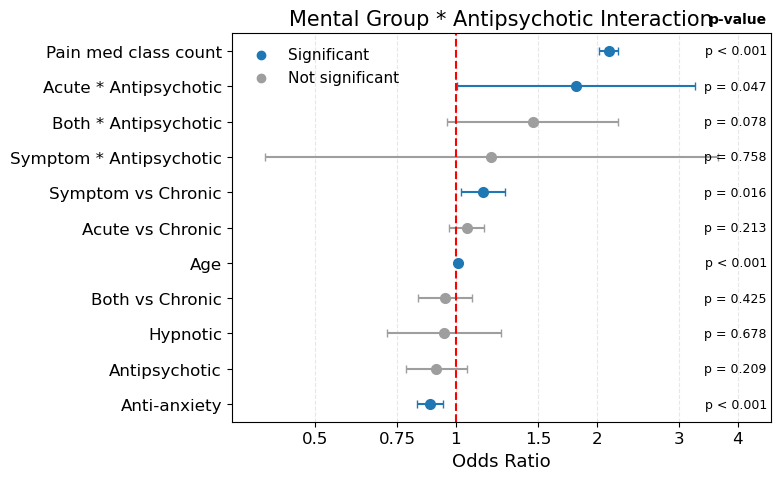

In [375]:
model_10 = smf.logit(
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) + Mental_Diagnosis_count+ "
    "Pre_existing_condition_count + Multimorbidity_count + "
    "C(Overall_Mental_group) * mental_antipsychotic + "
    "mental_antipsychotic + "
    "mental_anti_anxiety + mental_hypnotic + "
    "Pain_related_medication_class_count",
    data=train_df
).fit()
print(model_10.summary())


summary_df10 = model_10.summary2().tables[1]

or_df10 = summary_df9.copy()
or_df10["OR"] = np.exp(or_df10["Coef."])
or_df10["CI_low"] = np.exp(or_df10["Coef."] - 1.96 * or_df10["Std.Err."])
or_df10["CI_high"] = np.exp(or_df10["Coef."] + 1.96 * or_df10["Std.Err."])

print(or_df10.round(3))


df = model_10.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})


df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)
df["term"] = df["term"].str.replace(":", " × ", regex=False)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F]",
    "acute",
    "both",
    "symptom",
    "mental_antidepressant",
    "acute × mental_antipsychotic",
    "both × mental_antipsychotic",
    "symptom × mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_antipsychotic",
    "mental_hypnotic",
    "Pain_related_medication_class_count",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F]": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "mental_antidepressant": "Antidepressant",
    "acute × mental_antipsychotic": "Acute * Antipsychotic",
    "both × mental_antipsychotic": "Both * Antipsychotic",
    "symptom × mental_antipsychotic": "Symptom * Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_antipsychotic": "Antipsychotic",
    "mental_hypnotic": "Hypnotic",
    "Pain_related_medication_class_count": "Pain med class count",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)


plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.3
ax.set_xlim(xmin, xmax)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        markersize=7
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        xmax * 0.98,
        i,
        p_text,
        ha="right",
        va="center",
        fontsize=9
    )


ax.axvline(1, linestyle="--", color="red", linewidth=1.5)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])
ax.text(
    xmax * 0.98,
    len(plot_df) - 0.2,
    "p-value",
    ha="right",
    fontsize=10,
    fontweight="bold"
)

# legend
ax.scatter([], [], color="#1f77b4", label="Significant")
ax.scatter([], [], color="#9e9e9e", label="Not significant")
ax.legend(frameon=False)

# labels
ax.set_xlabel("Odds Ratio")
ax.set_title("Mental Group * Antipsychotic Interaction")

# grid
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [376]:
full = (
    "MSK_Diagnosis_1yr ~ "
    "Age + C(Sex) + Age:C(Sex) + "
    "Pre_existing_condition_count + Multimorbidity_count + Mental_Diagnosis_count + "
    "C(Overall_Mental_group) + "
    "mental_antidepressant + mental_antipsychotic + "
    "mental_anti_anxiety + mental_hypnotic + "
    "pain_nsaid + pain_muscle_relaxant + pain_opioid + "
    # group * medication interactions
    "C(Overall_Mental_group):mental_antidepressant + "
    "C(Overall_Mental_group):mental_antipsychotic + "
    "C(Overall_Mental_group):mental_anti_anxiety + "
    "C(Overall_Mental_group):mental_hypnotic + "
    "C(Overall_Mental_group):pain_nsaid + "
    "C(Overall_Mental_group):pain_muscle_relaxant + "
    "C(Overall_Mental_group):pain_opioid"
)


In [377]:

df = pd.read_csv(OUTDIR / "df_1yr_from_long.csv").copy()

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["MSK_Diagnosis_1yr"] = pd.to_numeric(df["MSK_Diagnosis_1yr"], errors="coerce").fillna(0).astype(int)

group_col = "Overall_Mental_group"
groups = ["chronic", "acute", "both", "symptom"]

def mean_sd(x):
    return f"{x.mean():.1f} ± {x.std():.1f}"

def pct(x):
    return f"{x.mean()*100:.1f}%"

table = []

# header N
n_dict = {g: len(df[df[group_col]==g]) for g in groups}

# Age
row = {"Characteristic": "Age"}
for g in groups:
    row[g] = mean_sd(df[df[group_col]==g]["Age"])
table.append(row)

# Female
row = {"Characteristic": "Female, %"}
for g in groups:
    sub = df[df[group_col]==g]
    row[g] = pct(sub["Sex"]=="F")
table.append(row)

# Mental diagnosis count 
row = {"Characteristic": "Mental diagnosis count"}
for g in groups:
    row[g] = mean_sd(df[df[group_col]==g]["Mental_Diagnosis_count"])
table.append(row)

# Pre-existing
row = {"Characteristic": "Pre-existing conditions"}
for g in groups:
    row[g] = mean_sd(df[df[group_col]==g]["Pre_existing_condition_count"])
table.append(row)

# Multimorbidity
row = {"Characteristic": "Multimorbidity count"}
for g in groups:
    row[g] = mean_sd(df[df[group_col]==g]["Multimorbidity_count"])
table.append(row)

# Mental_related_medication_class_count
row = {"Characteristic": "Mental-related medication count"}
for g in groups:
    row[g] = mean_sd(df[df[group_col]==g]["Mental_related_medication_class_count"])
table.append(row)

# Pain med
row = {"Characteristic": "Pain-related medication count"}
for g in groups:
    row[g] = mean_sd(df[df[group_col]==g]["Pain_related_medication_class_count"])
table.append(row)

# MSK outcome
row = {"Characteristic": "MSK within 1 year, %"}
for g in groups:
    row[g] = pct(df[df[group_col]==g]["MSK_Diagnosis_1yr"])
table.append(row)

table_df = pd.DataFrame(table)

# rename columns with n
table_df.columns = ["Characteristic"] + [
    f"{g.capitalize()} (n={n_dict[g]})" for g in groups
]

table_df

,Characteristic,Chronic (n=29656),Acute (n=4056),Both (n=2466),Symptom (n=2253)
0,Age,47.7 ± 16.4,46.9 ± 15.1,45.3 ± 14.6,49.8 ± 16.9
1,"Female, %",64.6%,71.3%,74.2%,65.5%
2,Mental diagnosis count,1.2 ± 0.5,1.1 ± 0.3,2.4 ± 0.7,1.0 ± 0.0
3,Pre-existing conditions,0.9 ± 1.0,1.1 ± 1.1,0.8 ± 1.0,1.1 ± 1.1
4,Multimorbidity count,0.8 ± 0.9,0.9 ± 0.9,1.0 ± 1.0,0.9 ± 1.0
5,Mental-related medication count,0.7 ± 0.7,0.4 ± 0.6,1.0 ± 0.8,0.4 ± 0.6
6,Pain-related medication count,0.2 ± 0.5,0.2 ± 0.5,0.3 ± 0.6,0.3 ± 0.5
7,"MSK within 1 year, %",35.5%,38.0%,30.2%,40.8%


### Add pain med class

Optimization terminated successfully.
         Current function value: 0.618081
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          MSK_Diagnosis   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26884
Method:                           MLE   Df Model:                           16
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.05153
Time:                        16:11:27   Log-Likelihood:                -16627.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------------------

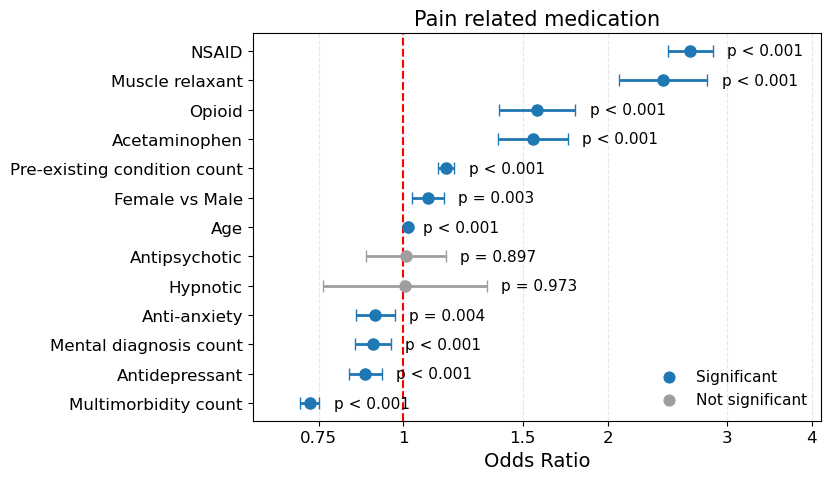

In [378]:
model_11 = smf.logit(
    formula="""
    MSK_Diagnosis ~ 
    Age
    + C(Sex)
    + C(Overall_Mental_group, Treatment(reference="chronic"))
    + Mental_Diagnosis_count
    + Pre_existing_condition_count
    + Multimorbidity_count

    + mental_antidepressant
    + mental_antipsychotic
    + mental_anti_anxiety
    + mental_hypnotic

    + pain_acetaminophen
    + pain_muscle_relaxant
    + pain_nsaid
    + pain_opioid
    """,
    data=train_df
).fit()
print(model_11.summary())


 
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11
})

df = model_11.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = df["term"].str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
df["term"] = df["term"].str.replace(r"\]", "", regex=True)
df["term"] = df["term"].str.replace(":", " × ", regex=False)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F",
    "acute",
    "both",
    "symptom",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",

    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",

    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_nsaid",
    "pain_opioid"
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing condition count",
    "Multimorbidity_count": "Multimorbidity count",

    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",

    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_nsaid": "NSAID",
    "pain_opioid": "Opioid"
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.30
ax.set_xlim(xmin, xmax * 1.11)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

# legend
ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="lower right", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Pain related medication", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Optimization terminated successfully.
         Current function value: 0.617969
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          MSK_Diagnosis   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26881
Method:                           MLE   Df Model:                           19
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.05170
Time:                        16:11:32   Log-Likelihood:                -16624.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                            coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------

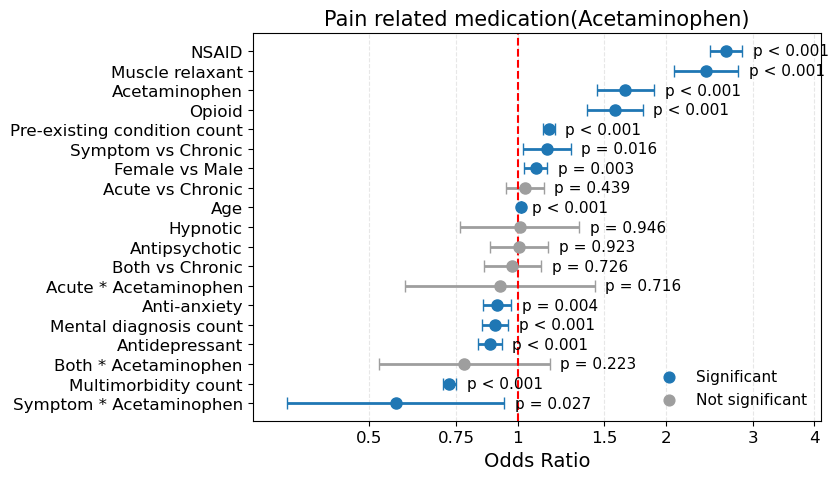

In [379]:
model_12 = smf.logit(
    formula="""
    MSK_Diagnosis ~ 
    Age
    + C(Sex)
    + C(Overall_Mental_group, Treatment(reference="chronic"))
    + Mental_Diagnosis_count
    + Pre_existing_condition_count
    + Multimorbidity_count

    + mental_antidepressant
    + mental_antipsychotic
    + mental_anti_anxiety
    + mental_hypnotic

    + pain_acetaminophen
    + pain_muscle_relaxant
    + pain_nsaid
    + pain_opioid

    + C(Overall_Mental_group, Treatment(reference="chronic")):pain_acetaminophen
    """,
    data=train_df
).fit()

print(model_12.summary())

df = model_12.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = (
    df["term"]
    .str.replace(r'C\(Overall_Mental_group, Treatment\(reference="chronic"\)\)\[T\.', "", regex=True)
    .str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
    .str.replace(r"\]", "", regex=True)
    .str.replace(":", " × ", regex=False)
)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F",
    "acute",
    "both",
    "symptom",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",

    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",

    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_nsaid",
    "pain_opioid",

    "acute × pain_acetaminophen",
    "both × pain_acetaminophen",
    "symptom × pain_acetaminophen",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing condition count",
    "Multimorbidity_count": "Multimorbidity count",

    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",

    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_nsaid": "NSAID",
    "pain_opioid": "Opioid",

    "acute × pain_acetaminophen": "Acute * Acetaminophen",
    "both × pain_acetaminophen": "Both * Acetaminophen",
    "symptom × pain_acetaminophen": "Symptom * Acetaminophen",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.30
ax.set_xlim(xmin, xmax * 1.11)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

# legend
ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="lower right", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Pain related medication(Acetaminophen)", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [380]:


params = model_12.params
cov = model_12.cov_params()

groups = ["chronic", "acute", "both", "symptom"]

rows = []

for g in groups:
    # chronic reference group: only pain_nsaid
    coef_names = ["pain_acetaminophen"]
    
    if g != "chronic":
        inter_name = (
            f'C(Overall_Mental_group, Treatment(reference="chronic"))'
            f'[T.{g}]:pain_acetaminophen'
        )
        coef_names.append(inter_name)

    beta = sum(params[name] for name in coef_names)

    # variance of sum(beta)
    var = 0
    for a in coef_names:
        for b in coef_names:
            var += cov.loc[a, b]

    se = np.sqrt(var)

    OR = np.exp(beta)
    CI_low = np.exp(beta - 1.96 * se)
    CI_high = np.exp(beta + 1.96 * se)
    z = beta / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))

    rows.append({
        "Mental_group": g,
        "OR_Acetaminophen": OR,
        "CI_low": CI_low,
        "CI_high": CI_high,
        "p_value": p
    })

acetaminophen_or_by_group = pd.DataFrame(rows)
acetaminophen_or_by_group["p_display"] = acetaminophen_or_by_group["p_value"].apply(
    lambda x: "p < 0.001" if x < 0.001 else f"p = {x:.3f}"
)

acetaminophen_or_by_group

,Mental_group,OR_Acetaminophen,CI_low,CI_high,p_value,p_display
0,chronic,1.655015,1.446002,1.894240,2.589040e-13,p < 0.001
1,acute,1.524053,0.997747,2.327983,5.122823e-02,p = 0.051
2,both,1.290651,0.884380,1.883558,1.858586e-01,p = 0.186
3,symptom,0.937038,0.575257,1.526345,7.939067e-01,p = 0.794


Optimization terminated successfully.
         Current function value: 0.617930
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          MSK_Diagnosis   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26881
Method:                           MLE   Df Model:                           19
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.05176
Time:                        16:11:35   Log-Likelihood:                -16623.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------

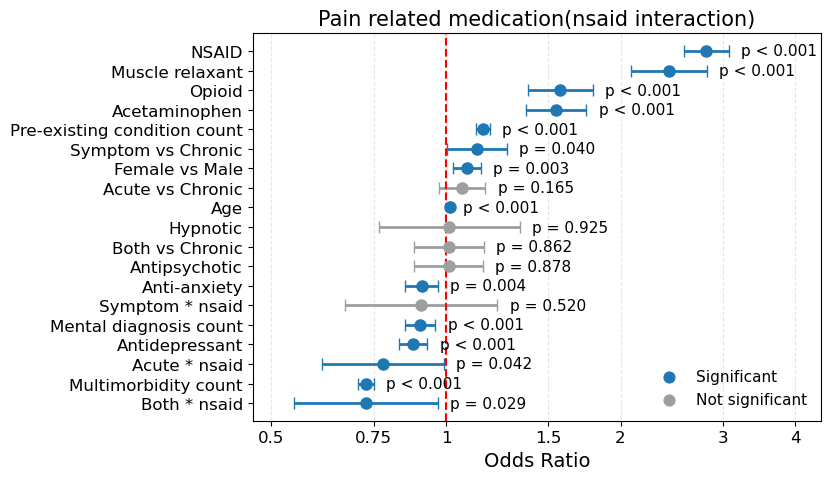

In [381]:
model_13 = smf.logit(
    formula="""
    MSK_Diagnosis ~ 
    Age
    + C(Sex)
    + C(Overall_Mental_group, Treatment(reference="chronic"))
    + Mental_Diagnosis_count
    + Pre_existing_condition_count
    + Multimorbidity_count

    + mental_antidepressant
    + mental_antipsychotic
    + mental_anti_anxiety
    + mental_hypnotic

    + pain_acetaminophen
    + pain_muscle_relaxant
    + pain_nsaid
    + pain_opioid

    + C(Overall_Mental_group, Treatment(reference="chronic")):pain_nsaid
    """,
    data=train_df
).fit()

print(model_13.summary())

df = model_13.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = (
    df["term"]
    .str.replace(r'C\(Overall_Mental_group, Treatment\(reference="chronic"\)\)\[T\.', "", regex=True)
    .str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
    .str.replace(r"\]", "", regex=True)
    .str.replace(":", " × ", regex=False)
)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F",
    "acute",
    "both",
    "symptom",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",

    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",

    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_nsaid",
    "pain_opioid",

    "acute × pain_nsaid",
    "both × pain_nsaid",
    "symptom × pain_nsaid",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing condition count",
    "Multimorbidity_count": "Multimorbidity count",

    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",

    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_nsaid": "NSAID",
    "pain_opioid": "Opioid",

    "acute × pain_nsaid": "Acute * nsaid",
    "both × pain_nsaid": "Both * nsaid",
    "symptom × pain_nsaid": "Symptom * nsaid",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.30
ax.set_xlim(xmin, xmax * 1.11)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

# legend
ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="lower right", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Pain related medication(nsaid interaction)", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [382]:
import numpy as np
import pandas as pd

params = model_13.params
cov = model_13.cov_params()

groups = ["chronic", "acute", "both", "symptom"]

rows = []

for g in groups:
    # chronic reference group: only pain_nsaid
    coef_names = ["pain_nsaid"]
    
    if g != "chronic":
        inter_name = (
            f'C(Overall_Mental_group, Treatment(reference="chronic"))'
            f'[T.{g}]:pain_nsaid'
        )
        coef_names.append(inter_name)

    beta = sum(params[name] for name in coef_names)

    # variance of sum(beta)
    var = 0
    for a in coef_names:
        for b in coef_names:
            var += cov.loc[a, b]

    se = np.sqrt(var)

    OR = np.exp(beta)
    CI_low = np.exp(beta - 1.96 * se)
    CI_high = np.exp(beta + 1.96 * se)
    z = beta / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))

    rows.append({
        "Mental_group": g,
        "OR_NSAID": OR,
        "CI_low": CI_low,
        "CI_high": CI_high,
        "p_value": p
    })

nsaid_or_by_group = pd.DataFrame(rows)
nsaid_or_by_group["p_display"] = nsaid_or_by_group["p_value"].apply(
    lambda x: "p < 0.001" if x < 0.001 else f"p = {x:.3f}"
)

nsaid_or_by_group

,Mental_group,OR_NSAID,CI_low,CI_high,p_value,p_display
0,chronic,2.811006,2.571797,3.072464,0.000000e+00,p < 0.001
1,acute,2.189432,1.749310,2.740289,7.700729e-12,p < 0.001
2,both,2.042505,1.554877,2.683060,2.873759e-07,p < 0.001
3,symptom,2.545103,1.904066,3.401955,2.793834e-10,p < 0.001


Optimization terminated successfully.
         Current function value: 0.617938
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          MSK_Diagnosis   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26881
Method:                           MLE   Df Model:                           19
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.05175
Time:                        16:11:39   Log-Likelihood:                -16623.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                              coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------

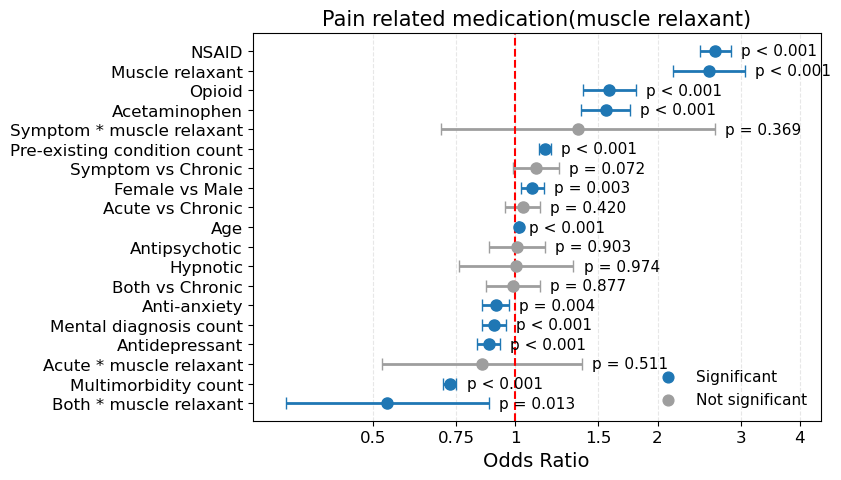

In [383]:
model_14 = smf.logit(
    formula="""
    MSK_Diagnosis ~ 
    Age
    + C(Sex)
    + C(Overall_Mental_group, Treatment(reference="chronic"))
    + Mental_Diagnosis_count
    + Pre_existing_condition_count
    + Multimorbidity_count

    + mental_antidepressant
    + mental_antipsychotic
    + mental_anti_anxiety
    + mental_hypnotic

    + pain_acetaminophen
    + pain_muscle_relaxant
    + pain_nsaid
    + pain_opioid

    + C(Overall_Mental_group, Treatment(reference="chronic")):pain_muscle_relaxant
    """,
    data=train_df
).fit()

print(model_14.summary())

df = model_14.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = (
    df["term"]
    .str.replace(r'C\(Overall_Mental_group, Treatment\(reference="chronic"\)\)\[T\.', "", regex=True)
    .str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
    .str.replace(r"\]", "", regex=True)
    .str.replace(":", " × ", regex=False)
)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F",
    "acute",
    "both",
    "symptom",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",

    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",

    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_nsaid",
    "pain_opioid",

    "acute × pain_muscle_relaxant",
    "both × pain_muscle_relaxant",
    "symptom × pain_muscle_relaxant",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing condition count",
    "Multimorbidity_count": "Multimorbidity count",

    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",

    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_nsaid": "NSAID",
    "pain_opioid": "Opioid",

    "acute × pain_muscle_relaxant": "Acute * muscle relaxant",
    "both × pain_muscle_relaxant": "Both * muscle relaxant",
    "symptom × pain_muscle_relaxant": "Symptom * muscle relaxant",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.30
ax.set_xlim(xmin, xmax * 1.11)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

# legend
ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="lower right", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Pain related medication(muscle relaxant)", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [384]:
from scipy import stats
import numpy as np
import pandas as pd

params = model_14.params
cov = model_14.cov_params()

groups = ["chronic", "acute", "both", "symptom"]

rows = []

for g in groups:
    coef_names = ["pain_muscle_relaxant"]

    if g != "chronic":
        inter_name = (
            f'C(Overall_Mental_group, Treatment(reference="chronic"))'
            f'[T.{g}]:pain_muscle_relaxant'
        )
        coef_names.append(inter_name)

    beta = 0
    valid_names = []

    for name in coef_names:
        if name in params:
            beta += params[name]
            valid_names.append(name)

    var = 0
    for a in valid_names:
        for b in valid_names:
            var += cov.loc[a, b]

    se = np.sqrt(var)

    OR = np.exp(beta)
    CI_low = np.exp(beta - 1.96 * se)
    CI_high = np.exp(beta + 1.96 * se)
    z = beta / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))

    rows.append({
        "Mental_group": g,
        "OR_Muscle_relaxant": OR,
        "CI_low": CI_low,
        "CI_high": CI_high,
        "p_value": p
    })

muscle_or_by_group = pd.DataFrame(rows)
muscle_or_by_group["p_display"] = muscle_or_by_group["p_value"].apply(
    lambda x: "p < 0.001" if x < 0.001 else f"p = {x:.3f}"
)

muscle_or_by_group

,Mental_group,OR_Muscle_relaxant,CI_low,CI_high,p_value,p_display
0,chronic,2.574760,2.161376,3.067208,0.000000,p < 0.001
1,acute,2.186813,1.385846,3.450711,0.000773,p < 0.001
2,both,1.381664,0.870052,2.194117,0.170665,p = 0.171
3,symptom,3.498819,1.834445,6.673266,0.000144,p < 0.001


Optimization terminated successfully.
         Current function value: 0.617947
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          MSK_Diagnosis   No. Observations:                26901
Model:                          Logit   Df Residuals:                    26881
Method:                           MLE   Df Model:                           19
Date:                Fri, 01 May 2026   Pseudo R-squ.:                 0.05173
Time:                        16:11:43   Log-Likelihood:                -16623.
converged:                       True   LL-Null:                       -17530.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------

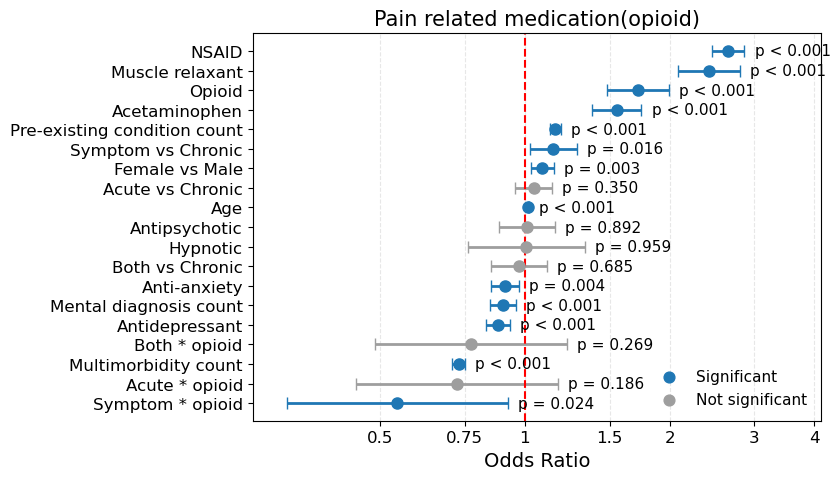

In [385]:
model_15 = smf.logit(
    formula="""
    MSK_Diagnosis ~ 
    Age
    + C(Sex)
    + C(Overall_Mental_group, Treatment(reference="chronic"))
    + Mental_Diagnosis_count
    + Pre_existing_condition_count
    + Multimorbidity_count

    + mental_antidepressant
    + mental_antipsychotic
    + mental_anti_anxiety
    + mental_hypnotic

    + pain_acetaminophen
    + pain_muscle_relaxant
    + pain_nsaid
    + pain_opioid

    + C(Overall_Mental_group, Treatment(reference="chronic")):pain_opioid
    """,
    data=train_df
).fit()

print(model_15.summary())

df = model_15.summary2().tables[1].copy()

df["OR"] = np.exp(df["Coef."])
df["CI_low"] = np.exp(df["Coef."] - 1.96 * df["Std.Err."])
df["CI_high"] = np.exp(df["Coef."] + 1.96 * df["Std.Err."])
df["sig"] = df["P>|z|"] < 0.05

df = df.reset_index().rename(columns={"index": "term"})

df["term"] = (
    df["term"]
    .str.replace(r'C\(Overall_Mental_group, Treatment\(reference="chronic"\)\)\[T\.', "", regex=True)
    .str.replace(r"C\(Overall_Mental_group\)\[T\.", "", regex=True)
    .str.replace(r"\]", "", regex=True)
    .str.replace(":", " × ", regex=False)
)

df = df[df["term"] != "Intercept"].copy()

keep_terms = [
    "Age",
    "C(Sex)[T.F",
    "acute",
    "both",
    "symptom",
    "Mental_Diagnosis_count",
    "Pre_existing_condition_count",
    "Multimorbidity_count",

    "mental_antidepressant",
    "mental_antipsychotic",
    "mental_anti_anxiety",
    "mental_hypnotic",

    "pain_acetaminophen",
    "pain_muscle_relaxant",
    "pain_nsaid",
    "pain_opioid",

    "acute × pain_opioid",
    "both × pain_opioid",
    "symptom × pain_opioid",
]

plot_df = df[df["term"].isin(keep_terms)].copy()

label_map = {
    "Age": "Age",
    "C(Sex)[T.F": "Female vs Male",
    "acute": "Acute vs Chronic",
    "both": "Both vs Chronic",
    "symptom": "Symptom vs Chronic",
    "Mental_Diagnosis_count": "Mental diagnosis count",
    "Pre_existing_condition_count": "Pre-existing condition count",
    "Multimorbidity_count": "Multimorbidity count",

    "mental_antidepressant": "Antidepressant",
    "mental_antipsychotic": "Antipsychotic",
    "mental_anti_anxiety": "Anti-anxiety",
    "mental_hypnotic": "Hypnotic",

    "pain_acetaminophen": "Acetaminophen",
    "pain_muscle_relaxant": "Muscle relaxant",
    "pain_nsaid": "NSAID",
    "pain_opioid": "Opioid",

    "acute × pain_opioid": "Acute * opioid",
    "both × pain_opioid": "Both * opioid",
    "symptom × pain_opioid": "Symptom * opioid",
}

plot_df["label"] = plot_df["term"].map(label_map)
plot_df = plot_df.sort_values("OR").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xscale("log")

xmin = plot_df["CI_low"].min() * 0.85
xmax = plot_df["CI_high"].max() * 1.30
ax.set_xlim(xmin, xmax * 1.11)

ticks = [0.5, 0.75, 1, 1.5, 2, 3, 4]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FixedFormatter([str(t) for t in ticks]))
ax.xaxis.set_minor_locator(mticker.NullLocator())

for i, row in plot_df.iterrows():
    color = "#1f77b4" if row["sig"] else "#9e9e9e"

    ax.errorbar(
        x=row["OR"],
        y=i,
        xerr=[[row["OR"] - row["CI_low"]], [row["CI_high"] - row["OR"]]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2,
        capsize=4,
        markersize=8
    )

    p_val = row["P>|z|"]
    if p_val < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p_val:.3f}"

    ax.text(
        row["CI_high"] * 1.05,
        i,
        p_text,
        ha="left",
        va="center",
        fontsize=11,
        color="black"
    )

ax.axvline(1, linestyle="--", color="red", linewidth=1.5)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["label"])

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

# legend
ax.scatter([], [], color="#1f77b4", s=60, label="Significant")
ax.scatter([], [], color="#9e9e9e", s=60, label="Not significant")
ax.legend(frameon=False, loc="lower right", title=None)

ax.set_xlabel("Odds Ratio", fontsize=14)
ax.set_title("Pain related medication(opioid)", fontsize=15)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [386]:


params = model_15.params
cov = model_15.cov_params()

groups = ["chronic", "acute", "both", "symptom"]

rows = []

for g in groups:
    coef_names = ["pain_opioid"]

    if g != "chronic":
        inter_name = (
            f'C(Overall_Mental_group, Treatment(reference="chronic"))'
            f'[T.{g}]:pain_opioid'
        )
        coef_names.append(inter_name)

    beta = 0
    valid_names = []

    for name in coef_names:
        if name in params:
            beta += params[name]
            valid_names.append(name)

    var = 0
    for a in valid_names:
        for b in valid_names:
            var += cov.loc[a, b]

    se = np.sqrt(var)

    OR = np.exp(beta)
    CI_low = np.exp(beta - 1.96 * se)
    CI_high = np.exp(beta + 1.96 * se)
    z = beta / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))

    rows.append({
        "Mental_group": g,
        "OR_opioid": OR,
        "CI_low": CI_low,
        "CI_high": CI_high,
        "p_value": p
    })

opioid_or_by_group = pd.DataFrame(rows)
opioid_or_by_group["p_display"] = opioid_or_by_group["p_value"].apply(
    lambda x: "p < 0.001" if x < 0.001 else f"p = {x:.3f}"
)

opioid_or_by_group

,Mental_group,OR_opioid,CI_low,CI_high,p_value,p_display
0,chronic,1.718348,1.483724,1.990074,4.916068e-13,p < 0.001
1,acute,1.239537,0.781071,1.967110,3.621108e-01,p = 0.362
2,both,1.325357,0.855534,2.053187,2.071910e-01,p = 0.207
3,symptom,0.932303,0.559930,1.552320,7.875660e-01,p = 0.788
